<a href="https://colab.research.google.com/github/Yisihaq01/breast-histology-calibration/blob/main/Notebooks/08_efficientnet_b0_independent_test_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Stage 8 — Independent Test Evaluation Under Magnification Shift

## Objective

Evaluate the final EfficientNet-B0 breast histopathology classifier and its two locked post-hoc calibration methods on completely unseen BreaKHis Test patients.

## Experimental Protocol

The final CNN was trained on 49 Development patients and its weights were frozen after five predetermined epochs.

Temperature scaling and Platt scaling were fitted using only the separate 16-patient Calibration partition.

Both calibrators are now locked.

We will evaluate three probability outputs:

1. Uncalibrated EfficientNet-B0
2. Temperature-scaled EfficientNet-B0
3. Platt-scaled EfficientNet-B0

Evaluation will cover four BreaKHis magnifications: 40×, 100×, 200×, and 400×.

The 40× Test set provides the primary same-magnification evaluation. The other magnifications assess changes in performance and probability reliability under magnification shift.

The primary image-level score is the arithmetic mean of patch logits.

## Metrics and Statistical Analysis

For each magnification and method, we will calculate AUROC, AUPRC, balanced accuracy, ECE with ten bins, Brier score, and negative log-likelihood.

Because multiple images belong to the same patient, statistical uncertainty will be assessed using patient-level resampling rather than treating images or patches as independent subjects.

## Test Data Isolation

No CNN parameters, calibration parameters, classification thresholds, or preprocessing rules will be optimized using Test results.

The locked model and calibrators will be applied without refitting.

Test results will be used for evaluation and reporting, not model selection.


In [1]:

# ============================================================
# Environment, Locked Calibration, and Frozen Test Audit
# ============================================================

import json
import hashlib
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import torch

# ------------------------------------------------------------
# 1. Locate or clone the repository
# ------------------------------------------------------------

REPO_ROOT = Path(
    "/content/breast-histology-calibration"
)

REPO_URL = (
    "https://github.com/Yisihaq01/"
    "breast-histology-calibration.git"
)

if not REPO_ROOT.exists():

    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_ROOT)],
        check=True
    )

    print("Repository cloned.")

else:
    print("Existing repository located.")

assert (REPO_ROOT / ".git").is_dir()

git_commit = subprocess.check_output(
    [
        "git",
        "-C",
        str(REPO_ROOT),
        "rev-parse",
        "--short",
        "HEAD"
    ],
    text=True
).strip()

assert torch.cuda.is_available(), (
    "Select a GPU runtime in Colab."
)

DEVICE = torch.device("cuda")

print("=" * 70)
print("STAGE 8 — ENVIRONMENT")
print("=" * 70)

print("Repository:", REPO_ROOT)
print("Git commit:", git_commit)
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 2. Reusable SHA-256 helper
# ------------------------------------------------------------

def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


# ------------------------------------------------------------
# 3. Verify final model provenance from Stage 6
# ------------------------------------------------------------

STAGE6_RESULTS_DIR = (
    REPO_ROOT /
    "results/final_development/efficientnet_b0"
)

completion_path = (
    STAGE6_RESULTS_DIR /
    "final_training_completion.json"
)

assert completion_path.is_file(), (
    "Stage 6 completion metadata missing."
)

with open(completion_path, encoding="utf-8") as f:
    completion = json.load(f)

EXPECTED_MODEL_SHA256 = (
    "84ea0871a309f3d68b8958b68b6da4f01adb31d3109fa4e0fc57f6670b63c9bb"
)

assert completion["training_completed"] is True
assert completion["epochs_completed"] == 5

assert completion["checkpoint_sha256"] == (
    EXPECTED_MODEL_SHA256
)

print("\nPASS: Final EfficientNet-B0 provenance verified.")

# ------------------------------------------------------------
# 4. Verify locked Stage 7 calibration artifacts
# ------------------------------------------------------------

STAGE7_RESULTS_DIR = (
    REPO_ROOT /
    "results/posthoc_calibration/efficientnet_b0"
)

LOCK_PATH = (
    STAGE7_RESULTS_DIR /
    "calibration_lock_record.json"
)

PARAMETERS_PATH = (
    STAGE7_RESULTS_DIR /
    "calibration_fitted_parameters.json"
)

CALIBRATION_MANIFEST_PATH = (
    REPO_ROOT /
    "Metadata/breakhis_calibration_40x_patch_manifest.csv"
)

assert LOCK_PATH.is_file(), (
    "Stage 7 lock record is missing. "
    "Ensure the Stage 7 results were committed "
    "and pushed to GitHub."
)

assert PARAMETERS_PATH.is_file(), (
    "Stage 7 calibration parameters are missing."
)

assert CALIBRATION_MANIFEST_PATH.is_file()

with open(LOCK_PATH, encoding="utf-8") as f:
    calibration_lock = json.load(f)

with open(PARAMETERS_PATH, encoding="utf-8") as f:
    calibration_parameters = json.load(f)

assert calibration_lock["status"] == (
    "completed_and_locked"
)

assert calibration_lock[
    "final_checkpoint_sha256"
] == EXPECTED_MODEL_SHA256

assert calibration_lock[
    "calibration_parameters_sha256"
] == sha256_file(PARAMETERS_PATH)

assert calibration_lock[
    "calibration_manifest_sha256"
] == sha256_file(CALIBRATION_MANIFEST_PATH)

assert calibration_lock[
    "test_data_used_for_fitting"
] is False

assert calibration_lock[
    "calibrator_selection_using_test"
] is False

# Recover exact fitted values from saved records.
LOCKED_TEMPERATURE = float(
    calibration_parameters[
        "temperature_scaling"
    ]["temperature"]
)

LOCKED_PLATT_SLOPE = float(
    calibration_parameters[
        "platt_scaling"
    ]["slope"]
)

LOCKED_PLATT_INTERCEPT = float(
    calibration_parameters[
        "platt_scaling"
    ]["intercept"]
)

assert LOCKED_TEMPERATURE > 0
assert LOCKED_PLATT_SLOPE > 0

assert LOCKED_TEMPERATURE == float(
    calibration_lock["temperature_scaling"]["temperature"]
)

assert LOCKED_PLATT_SLOPE == float(
    calibration_lock["platt_scaling"]["slope"]
)

assert LOCKED_PLATT_INTERCEPT == float(
    calibration_lock["platt_scaling"]["intercept"]
)

print("\n" + "=" * 70)
print("LOCKED STAGE 7 CALIBRATION")
print("=" * 70)

print("Temperature:", LOCKED_TEMPERATURE)
print("Platt slope:", LOCKED_PLATT_SLOPE)
print("Platt intercept:", LOCKED_PLATT_INTERCEPT)

print("\nPASS: Stage 7 calibration lock verified.")
print("PASS: Calibration parameter SHA-256 verified.")
print("PASS: Both calibrators remain unchanged.")

# ------------------------------------------------------------
# 5. Load original frozen patient assignments
# ------------------------------------------------------------

PATIENT_SPLIT_PATH = (
    REPO_ROOT /
    "Metadata/breakhis_patient_split.csv"
)

assert PATIENT_SPLIT_PATH.is_file()

patient_splits = pd.read_csv(
    PATIENT_SPLIT_PATH,
    dtype={"patient_id": str}
)

assert patient_splits["patient_id"].is_unique

patient_splits["split_normalized"] = (
    patient_splits["split"]
    .astype(str)
    .str.strip()
    .str.lower()
)

development_patients = set(
    patient_splits.loc[
        patient_splits["split_normalized"] == "development",
        "patient_id"
    ]
)

calibration_patients = set(
    patient_splits.loc[
        patient_splits["split_normalized"] == "calibration",
        "patient_id"
    ]
)

test_patients = set(
    patient_splits.loc[
        patient_splits["split_normalized"] == "test",
        "patient_id"
    ]
)

assert len(development_patients) == 49
assert len(calibration_patients) == 16
assert len(test_patients) == 16

assert development_patients.isdisjoint(
    calibration_patients
)

assert development_patients.isdisjoint(
    test_patients
)

assert calibration_patients.isdisjoint(
    test_patients
)

print("\n" + "=" * 70)
print("FROZEN PATIENT SPLITS")
print("=" * 70)

print(
    patient_splits["split_normalized"]
    .value_counts()
    .to_string()
)

print("\nPASS: All three patient partitions verified.")
print("PASS: No patient overlap.")

# ------------------------------------------------------------
# 6. Load all-magnification finalized metadata
# ------------------------------------------------------------

ALL_MAG_METADATA_PATH = (
    REPO_ROOT /
    "Metadata/breakhis_all_magnification_final_metadata.csv"
)

assert ALL_MAG_METADATA_PATH.is_file()

all_magnification_metadata = pd.read_csv(
    ALL_MAG_METADATA_PATH,
    dtype={"patient_id": str}
)

print("\n" + "=" * 70)
print("ALL-MAGNIFICATION METADATA SCHEMA")
print("=" * 70)

print(all_magnification_metadata.columns.tolist())

required_columns = {
    "filename",
    "relative_path",
    "patient_id",
    "magnification",
    "diagnosis"
}

assert required_columns.issubset(
    all_magnification_metadata.columns
)

# Normalize magnification values, whether stored as
# 40, "40", or "40X".

all_magnification_metadata["magnification_numeric"] = (
    pd.to_numeric(
        all_magnification_metadata["magnification"]
        .astype(str)
        .str.strip()
        .str.lower()
        .str.replace("x", "", regex=False),
        errors="raise"
    ).astype(int)
)

assert set(
    all_magnification_metadata[
        "magnification_numeric"
    ].unique()
).issubset({40, 100, 200, 400})

# ------------------------------------------------------------
# 7. Select original frozen Test records
# ------------------------------------------------------------

test_images = (
    all_magnification_metadata.loc[
        all_magnification_metadata["patient_id"]
        .isin(test_patients)
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(test_images) > 0

assert test_images["patient_id"].nunique() == 16

assert set(test_images["patient_id"]) == (
    test_patients
)

assert test_images["filename"].is_unique

assert test_images["relative_path"].is_unique

assert test_images[
    ["filename", "relative_path", "patient_id",
     "magnification_numeric", "diagnosis"]
].notna().all().all()

assert set(
    test_images["magnification_numeric"].unique()
) == {40, 100, 200, 400}

assert set(test_images["patient_id"]).isdisjoint(
    development_patients | calibration_patients
)

# If frozen split labels are also stored at image level,
# verify they match the patient-level assignments.

if "split" in test_images.columns:

    assert (
        test_images["split"]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("test")
        .all()
    )

# Verify consistent diagnostic assignment per patient.
assert (
    test_images.groupby("patient_id")[
        "diagnosis"
    ].nunique().max()
) == 1

# ------------------------------------------------------------
# 8. Summarize Test coverage by magnification
# ------------------------------------------------------------

test_magnification_summary = (
    test_images
    .groupby("magnification_numeric")
    .agg(
        images=("filename", "nunique"),
        patients=("patient_id", "nunique")
    )
    .reset_index()
    .sort_values("magnification_numeric")
)

assert len(test_magnification_summary) == 4

assert (
    test_magnification_summary["images"] > 0
).all()

print("\n" + "=" * 70)
print("INDEPENDENT TEST COHORT")
print("=" * 70)

print("Unique Test patients:", len(test_patients))
print("Total Test images:", len(test_images))

print("\nImages by magnification:")
display(test_magnification_summary)

print("\nTest diagnosis distribution:")
print(
    test_images["diagnosis"]
    .value_counts()
    .to_string()
)

# ------------------------------------------------------------
# 9. Prepare Stage 8 output directory
# ------------------------------------------------------------

STAGE8_RESULTS_DIR = (
    REPO_ROOT /
    "results/independent_test/efficientnet_b0"
)

STAGE8_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 10. Final preflight report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STAGE 8 — INITIAL PREFLIGHT AUDIT")
print("=" * 70)

print("PASS: GitHub repository located.")
print("PASS: GPU runtime available.")
print("PASS: Final EfficientNet-B0 provenance verified.")
print("PASS: Stage 7 calibration lock verified.")
print("PASS: Exact calibration parameters recovered.")
print("PASS: 49 Development patients verified.")
print("PASS: 16 Calibration patients verified.")
print("PASS: 16 independent Test patients verified.")
print("PASS: All four magnifications represented.")
print("PASS: No patient overlap.")
print("PASS: Original Test metadata preserved.")
print("PASS: No CNN inference performed.")
print("PASS: No model or calibrator fitting performed.")
print("PASS: No Test metrics calculated.")


Repository cloned.
STAGE 8 — ENVIRONMENT
Repository: /content/breast-histology-calibration
Git commit: f39d115
PyTorch: 2.14.1+cu130
GPU: Tesla T4

PASS: Final EfficientNet-B0 provenance verified.

LOCKED STAGE 7 CALIBRATION
Temperature: 4.069193139210192
Platt slope: 0.29141657172422586
Platt intercept: -0.7096590060187311

PASS: Stage 7 calibration lock verified.
PASS: Calibration parameter SHA-256 verified.
PASS: Both calibrators remain unchanged.

FROZEN PATIENT SPLITS
split_normalized
development    49
calibration    16
test           16

PASS: All three patient partitions verified.
PASS: No patient overlap.

ALL-MAGNIFICATION METADATA SCHEMA
['filename', 'relative_path', 'patient_id', 'diagnosis_code', 'diagnosis', 'original_subtype_code', 'original_subtype', 'analysis_subtype_code', 'analysis_subtype', 'magnification', 'image_number', 'pixel_hash', 'duplicate_group_size', 'duplicate_rank', 'excluded_duplicate', 'split', 'split_key', 'primary_analysis_role']

INDEPENDENT TEST COH

,magnification_numeric,images,patients
0,40,446,16
1,100,501,16
2,200,480,16
3,400,436,16



Test diagnosis distribution:
diagnosis
Malignant    1142
Benign        721

STAGE 8 — INITIAL PREFLIGHT AUDIT
PASS: GitHub repository located.
PASS: GPU runtime available.
PASS: Final EfficientNet-B0 provenance verified.
PASS: Stage 7 calibration lock verified.
PASS: Exact calibration parameters recovered.
PASS: 49 Development patients verified.
PASS: 16 Calibration patients verified.
PASS: 16 independent Test patients verified.
PASS: All four magnifications represented.
PASS: No patient overlap.
PASS: Original Test metadata preserved.
PASS: No CNN inference performed.
PASS: No model or calibrator fitting performed.
PASS: No Test metrics calculated.


In [2]:

# ============================================================
# Test Eligibility and Magnification Preprocessing Audit
# ============================================================

import ast

# ------------------------------------------------------------
# 1. Verify the four Test magnification groups
# ------------------------------------------------------------

expected_counts = {
    40: 446,
    100: 501,
    200: 480,
    400: 436
}

actual_counts = (
    test_images["magnification_numeric"]
    .value_counts()
    .to_dict()
)

assert actual_counts == expected_counts
assert len(test_images) == 1863

print("=" * 70)
print("TEST MAGNIFICATION AND CLASS DISTRIBUTION")
print("=" * 70)

print(
    pd.crosstab(
        test_images["magnification_numeric"],
        test_images["diagnosis"],
        margins=True
    ).to_string()
)

# ------------------------------------------------------------
# 2. Examine original duplicate-exclusion flags
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DUPLICATE FLAGS")
print("=" * 70)

if "excluded_duplicate" in test_images.columns:

    duplicate_flags = (
        test_images["excluded_duplicate"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    flagged_duplicates = duplicate_flags.isin(
        {"true", "1", "yes"}
    )

    print(
        pd.crosstab(
            test_images["magnification_numeric"],
            duplicate_flags,
            margins=True
        ).to_string()
    )

    print(
        "\nRows flagged for duplicate exclusion:",
        int(flagged_duplicates.sum())
    )

else:
    print("No duplicate-exclusion column present.")

if "pixel_hash" in test_images.columns:

    print(
        "\nUnique pixel hashes:",
        test_images["pixel_hash"].nunique()
    )

    print(
        "Repeated pixel hashes:",
        int(
            test_images["pixel_hash"]
            .duplicated()
            .sum()
        )
    )

# ------------------------------------------------------------
# 3. Examine existing analysis-role assignments
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ORIGINAL ANALYSIS ROLES")
print("=" * 70)

if "primary_analysis_role" in test_images.columns:

    print(
        pd.crosstab(
            test_images["magnification_numeric"],
            test_images["primary_analysis_role"]
            .fillna("<missing>"),
            margins=True
        ).to_string()
    )

if "split_key" in test_images.columns:

    print("\nSplit-key summary:")

    print(
        test_images["split_key"]
        .value_counts(dropna=False)
        .head(20)
        .to_string()
    )

# ------------------------------------------------------------
# 4. Inspect original preprocessing and magnification code
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ORIGINAL MAGNIFICATION / RESAMPLING DEFINITIONS")
print("=" * 70)

notebook_paths = [
    REPO_ROOT /
    "Notebooks/01_breakhis_data_audit_and_split.ipynb",
    REPO_ROOT /
    "Notebooks/02_breakhis_all_magnification_audit.ipynb",
    REPO_ROOT /
    "Notebooks/03_breakhis_formal_development.ipynb"
]

search_tokens = (
    "SOURCE_MPP",
    "TARGET_MPP",
    "resample_to_target_mpp",
    "generate_grid_coordinates",
    "extract_tissue_patches",
    "PATCH_SIZE",
    "GRID_SIZE"
)

for notebook_path in notebook_paths:

    assert notebook_path.is_file()

    with open(
        notebook_path,
        encoding="utf-8"
    ) as f:
        notebook = json.load(f)

    print("\nFILE:", notebook_path.name)

    findings = []

    for cell_index, cell in enumerate(
        notebook["cells"]
    ):

        if cell.get("cell_type") != "code":
            continue

        source = "".join(
            cell.get("source", [])
        )

        try:
            tree = ast.parse(source)
        except SyntaxError:
            continue

        for node in tree.body:

            if isinstance(node, ast.FunctionDef):

                if node.name in {
                    "resample_to_target_mpp",
                    "generate_grid_coordinates",
                    "extract_tissue_patches"
                }:

                    findings.append((
                        cell_index,
                        ast.get_source_segment(source, node)
                    ))

            elif isinstance(
                node,
                (ast.Assign, ast.AnnAssign)
            ):

                targets = (
                    node.targets
                    if isinstance(node, ast.Assign)
                    else [node.target]
                )

                names = [
                    target.id
                    for target in targets
                    if isinstance(target, ast.Name)
                ]

                if any(
                    name.startswith((
                        "SOURCE_MPP",
                        "TARGET_MPP"
                    ))
                    or name in {"PATCH_SIZE", "GRID_SIZE"}
                    for name in names
                ):

                    findings.append((
                        cell_index,
                        ast.get_source_segment(source, node)
                    ))

    # Show the original definitions, not guessed values.
    for cell_index, source in findings[-12:]:

        if source is None:
            continue

        print(f"\nOriginal cell {cell_index}:")
        print(source[:3500])

    if not findings:
        print("No explicit resampling definitions found.")

# ------------------------------------------------------------
# 5. Examine source-image metadata without loading images
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TEST SOURCE IMAGE EXAMPLES")
print("=" * 70)

display(
    test_images.groupby(
        "magnification_numeric",
        group_keys=False
    ).head(1)[
        [
            "filename",
            "magnification_numeric",
            "relative_path",
            "diagnosis"
        ]
    ]
)

# ------------------------------------------------------------
# 6. Confirm the locked parameters remain unchanged
# ------------------------------------------------------------

assert LOCKED_TEMPERATURE == (
    4.069193139210192
)

assert np.isclose(
    LOCKED_PLATT_SLOPE,
    0.29141657172422586,
    rtol=0,
    atol=1e-14
)

assert np.isclose(
    LOCKED_PLATT_INTERCEPT,
    -0.7096590060187311,
    rtol=0,
    atol=1e-14
)

assert calibration_lock[
    "calibrator_selection_using_test"
] is False

assert set(test_images["patient_id"]) == test_patients

print("\n" + "=" * 70)
print("STAGE 8 — PREPROCESSING PREFLIGHT")
print("=" * 70)

print("PASS: All four Test image counts verified.")
print("PASS: Duplicate flags inspected.")
print("PASS: Original analysis roles inspected.")
print("PASS: Preprocessing source code inspected.")
print("PASS: Frozen Test patients unchanged.")
print("PASS: Temperature and Platt parameters unchanged.")
print("PASS: No Test inference performed.")
print("PASS: No calibrator refitting performed.")
print("PASS: No Test metrics calculated.")


TEST MAGNIFICATION AND CLASS DISTRIBUTION
diagnosis              Benign  Malignant   All
magnification_numeric                         
40                        175        271   446
100                       199        302   501
200                       168        312   480
400                       179        257   436
All                       721       1142  1863

DUPLICATE FLAGS
excluded_duplicate     false   All
magnification_numeric             
40                       446   446
100                      501   501
200                      480   480
400                      436   436
All                     1863  1863

Rows flagged for duplicate exclusion: 0

Unique pixel hashes: 1863
Repeated pixel hashes: 0

ORIGINAL ANALYSIS ROLES
primary_analysis_role  internal_clean_test  magnification_shift_test   All
magnification_numeric                                                     
40                                     446                         0   446
100                     

,filename,magnification_numeric,relative_path,diagnosis
0,SOB_M_LC-14-12204-100-053.png,100,BreaKHis_v1/BreaKHis_v1/histology_slides/breas...,Malignant
31,SOB_M_LC-14-12204-200-049.png,200,BreaKHis_v1/BreaKHis_v1/histology_slides/breas...,Malignant
59,SOB_M_LC-14-12204-40-005.png,40,BreaKHis_v1/BreaKHis_v1/histology_slides/breas...,Malignant
77,SOB_M_LC-14-12204-400-029.png,400,BreaKHis_v1/BreaKHis_v1/histology_slides/breas...,Malignant



STAGE 8 — PREPROCESSING PREFLIGHT
PASS: All four Test image counts verified.
PASS: Duplicate flags inspected.
PASS: Original analysis roles inspected.
PASS: Preprocessing source code inspected.
PASS: Frozen Test patients unchanged.
PASS: Temperature and Platt parameters unchanged.
PASS: No Test inference performed.
PASS: No calibrator refitting performed.
PASS: No Test metrics calculated.


In [3]:

# ============================================================
# Locked Preprocessing and Test Patch Manifest Generation
# ============================================================

import kagglehub
from PIL import Image
from matplotlib.colors import rgb_to_hsv

# ------------------------------------------------------------
# 1. Recover original preprocessing definitions
# ------------------------------------------------------------

SOURCE_NOTEBOOK_PATH = (
    REPO_ROOT /
    "Notebooks/01_breakhis_data_audit_and_split.ipynb"
)

with open(SOURCE_NOTEBOOK_PATH, encoding="utf-8") as f:
    source_notebook = json.load(f)

required_constants = {
    "SOURCE_MPP_BREAKHIS": 0.49,
    "TARGET_MPP": 0.50,
    "PATCH_SIZE": 224,
    "GRID_SIZE": 4,
    "MAX_PATCHES": 16,
    "MIN_PATCH_TISSUE_FRACTION": 0.20,
    "OD_THRESHOLD": 0.08,
    "SATURATION_THRESHOLD": 0.05
}

required_functions = [
    "resample_to_target_mpp",
    "create_tissue_mask_hybrid",
    "generate_grid_coordinates",
    "extract_tissue_patches",
    "build_patch_manifest"
]

found_constants = {}
found_functions = {}

for cell in source_notebook["cells"]:

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:

        if isinstance(node, ast.Assign):

            for target in node.targets:

                if (
                    isinstance(target, ast.Name)
                    and target.id in required_constants
                ):
                    value = ast.literal_eval(node.value)

                    found_constants.setdefault(
                        target.id, value
                    )

        if isinstance(node, ast.FunctionDef):

            if node.name in required_functions:
                found_functions.setdefault(
                    node.name,
                    ast.get_source_segment(source, node)
                )

assert set(found_constants) == set(required_constants)

for name, expected in required_constants.items():
    assert found_constants[name] == expected
    globals()[name] = expected

assert set(found_functions) == set(required_functions)

for name in required_functions:
    assert found_functions[name] is not None
    exec(found_functions[name], globals())

assert len(generate_grid_coordinates(686, 451)) == 16

print("PASS: Eight original preprocessing constants restored.")
print("PASS: Five original extraction functions restored.")
print("PASS: Original 4x4 patch grid verified.")

# ------------------------------------------------------------
# 2. Lock magnification-shift preprocessing policy
# ------------------------------------------------------------

# Reported effective physical pixel sizes.
# These are documentation, NOT per-image resize inputs.

REPORTED_MPP = {
    40: 0.49,
    100: 0.20,
    200: 0.10,
    400: 0.05
}

# Retain the original model's FIXED resize operator.
# At >40x, this does NOT achieve 0.50 um/pixel.

LOCKED_RESIZE_RATIO = (
    SOURCE_MPP_BREAKHIS / TARGET_MPP
)

assert np.isclose(LOCKED_RESIZE_RATIO, 0.98)

assert resample_to_target_mpp(
    Image.new("RGB", (700, 460))
).size == (686, 451)

print("PASS: Original 0.98 input resize operator locked.")
print("PASS: No magnification-specific resizing introduced.")

# ------------------------------------------------------------
# 3. Locate original BreaKHis source images
# ------------------------------------------------------------

DATASET_ROOT = Path(
    kagglehub.dataset_download("ambarish/breakhis")
)

# Original build_patch_manifest uses global 'root'.
root = DATASET_ROOT

assert DATASET_ROOT.is_dir()

missing_images = [
    str(path)
    for path in test_images["relative_path"]
    if not (DATASET_ROOT / path).is_file()
]

assert not missing_images, (
    f"Missing Test files: {missing_images[:5]}"
)

print("Dataset root:", DATASET_ROOT)
print("PASS: All 1,863 Test images located.")

# ------------------------------------------------------------
# 4. Reproduce two existing Development image manifests
# ------------------------------------------------------------

DEVELOPMENT_MANIFEST_PATH = (
    REPO_ROOT /
    "Metadata/breakhis_development_all_patch_manifest.csv"
)

development_manifest = pd.read_csv(
    DEVELOPMENT_MANIFEST_PATH,
    dtype={"patient_id": str}
)

verification_filenames = [
    "SOB_B_TA-14-13200-40-001.png",
    "SOB_M_MC-14-13418DE-40-001.png"
]

for filename in verification_filenames:

    original = (
        development_manifest.loc[
            development_manifest["filename"] == filename
        ]
        .sort_values("patch_index")
        .reset_index(drop=True)
    )

    assert len(original) > 0

    image_path = (
        DATASET_ROOT / original.iloc[0]["relative_path"]
    )

    with Image.open(image_path) as image:

        _, patch_info, used_fallback = (
            extract_tissue_patches(image.convert("RGB"))
        )

    reproduced = (
        pd.DataFrame(patch_info)
        .sort_values("patch_index")
        .reset_index(drop=True)
    )

    assert len(reproduced) == len(original)

    for column in ["patch_index", "x", "y"]:

        np.testing.assert_array_equal(
            reproduced[column].to_numpy(),
            original[column].to_numpy()
        )

    np.testing.assert_allclose(
        reproduced["tissue_fraction"].to_numpy(),
        original["tissue_fraction"].to_numpy(),
        rtol=0,
        atol=1e-8
    )

    assert bool(used_fallback) == bool(
        original["used_fallback"].iloc[0]
    )

    print("PASS: Original Development extraction:", filename)

# ------------------------------------------------------------
# 5. Generate or reuse one manifest per magnification
# ------------------------------------------------------------

TEST_MANIFEST_DIR = (
    REPO_ROOT / "Metadata"
)

test_manifest_parts = []
test_manifest_paths = {}

for magnification in [40, 100, 200, 400]:

    source_rows = (
        test_images.loc[
            test_images["magnification_numeric"]
            == magnification
        ]
        .copy()
        .reset_index(drop=True)
    )

    manifest_path = (
        TEST_MANIFEST_DIR /
        f"breakhis_test_{magnification}x_patch_manifest.csv"
    )

    print("\n" + "=" * 65)
    print(f"TEST PATCHES — {magnification}x")
    print("=" * 65)

    if manifest_path.is_file():

        print("Existing manifest found; verifying it.")

        part = pd.read_csv(
            manifest_path,
            dtype={"patient_id": str}
        )

    else:

        print(
            "Generating patches for",
            len(source_rows),
            "images."
        )

        part = build_patch_manifest(source_rows)

        part["magnification"] = magnification

    # Validate before accepting or saving this partition.

    assert "magnification" in part.columns

    assert (
        pd.to_numeric(part["magnification"])
        .eq(magnification)
        .all()
    )

    assert set(part["filename"]) == set(
        source_rows["filename"]
    )

    assert part["filename"].nunique() == len(source_rows)

    assert set(part["patient_id"]) == test_patients

    assert not part.duplicated(
        ["filename", "patch_index"]
    ).any()

    assert part["tissue_fraction"].between(0, 1).all()

    assert part.groupby("filename").size().between(
        1, MAX_PATCHES
    ).all()

    expected_metadata = (
        source_rows
        .set_index("filename")[
            ["patient_id", "relative_path", "diagnosis"]
        ]
    )

    observed_metadata = (
        part
        .set_index("filename")[
            ["patient_id", "relative_path", "diagnosis"]
        ]
    )

    for column in expected_metadata.columns:

        assert (
            observed_metadata[column].astype(str).to_numpy()
            ==
            expected_metadata.loc[
                observed_metadata.index, column
            ].astype(str).to_numpy()
        ).all()

    expected_labels = (
        part["diagnosis"].eq("Malignant").astype(int)
    )

    assert np.array_equal(
        part["label"].to_numpy(dtype=int),
        expected_labels.to_numpy()
    )

    if not manifest_path.is_file():

        part.to_csv(
            manifest_path,
            index=False,
            float_format="%.17g"
        )

    test_manifest_parts.append(part)
    test_manifest_paths[magnification] = manifest_path

    print("Images:", part["filename"].nunique())
    print("Patches:", len(part))
    print(
        "Fallback images:",
        part.loc[
            part["used_fallback"].astype(str)
            .str.lower().isin(["true", "1"]),
            "filename"
        ].nunique()
    )
    print("PASS: Manifest verified and saved.")

# ------------------------------------------------------------
# 6. Combine all four Test manifests
# ------------------------------------------------------------

test_patch_manifest = pd.concat(
    test_manifest_parts,
    ignore_index=True
)

assert test_patch_manifest["filename"].nunique() == 1863
assert test_patch_manifest["patient_id"].nunique() == 16

assert set(test_patch_manifest["patient_id"]) == (
    test_patients
)

assert not test_patch_manifest.duplicated(
    ["filename", "patch_index"]
).any()

assert (
    test_patch_manifest
    .groupby("magnification")["filename"]
    .nunique()
    .to_dict()
    ==
    {40: 446, 100: 501, 200: 480, 400: 436}
)

TEST_MANIFEST_PATH = (
    TEST_MANIFEST_DIR /
    "breakhis_test_all_magnification_patch_manifest.csv"
)

test_patch_manifest.to_csv(
    TEST_MANIFEST_PATH,
    index=False,
    float_format="%.17g"
)

assert len(pd.read_csv(TEST_MANIFEST_PATH)) == len(
    test_patch_manifest
)

# ------------------------------------------------------------
# 7. Save preprocessing and manifest audit
# ------------------------------------------------------------

manifest_summary = (
    test_patch_manifest
    .groupby("magnification")
    .agg(
        images=("filename", "nunique"),
        patients=("patient_id", "nunique"),
        patches=("patch_index", "size")
    )
    .reset_index()
)

audit = {
    "stage": 8,
    "status": "test_preprocessing_locked",
    "test_patients": 16,
    "test_images": 1863,
    "test_patches": int(len(test_patch_manifest)),
    "test_magnifications": [40, 100, 200, 400],
    "preprocessing_policy":
        "fixed_40x_development_input_operator_all_magnifications",
    "resize_ratio_all_magnifications":
        LOCKED_RESIZE_RATIO,
    "physical_resolution_normalized_across_magnifications":
        False,
    "source_mpp_reported_um_per_pixel":
        {str(k): v for k, v in REPORTED_MPP.items()},
    "physical_resolution_reference_doi":
        "10.1049/cvi2.12021",
    "patch_size": PATCH_SIZE,
    "grid_size": GRID_SIZE,
    "max_patches": MAX_PATCHES,
    "min_tissue_fraction": MIN_PATCH_TISSUE_FRACTION,
    "od_threshold": OD_THRESHOLD,
    "saturation_threshold": SATURATION_THRESHOLD,
    "source_preprocessing_sha256":
        sha256_file(SOURCE_NOTEBOOK_PATH),
    "final_cnn_checkpoint_sha256":
        EXPECTED_MODEL_SHA256,
    "locked_calibration_parameters_sha256":
        sha256_file(PARAMETERS_PATH),
    "combined_test_manifest_sha256":
        sha256_file(TEST_MANIFEST_PATH),
    "per_magnification_manifest_sha256": {
        str(m): sha256_file(p)
        for m, p in test_manifest_paths.items()
    },
    "cnn_inference_performed": False,
    "test_predictions_inspected": False,
    "test_labels_used_for_fitting": False,
    "calibration_parameters_changed": False
}

TEST_MANIFEST_AUDIT_PATH = (
    STAGE8_RESULTS_DIR /
    "test_patch_manifest_audit.json"
)

with open(
    TEST_MANIFEST_AUDIT_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(audit, f, indent=2)

print("\n" + "=" * 70)
print("INDEPENDENT TEST PATCH MANIFEST SUMMARY")
print("=" * 70)

display(manifest_summary)

print("Total Test images:", 1863)
print("Total Test patches:", len(test_patch_manifest))
print("Test patients:", 16)

print("\n" + "=" * 70)
print("STAGE 8 — CELL 4 FINAL AUDIT")
print("=" * 70)

print("PASS: Original Development preprocessing reproduced.")
print("PASS: All Test images located.")
print("PASS: Original tissue patch extraction reused.")
print("PASS: Fixed input geometry across magnifications.")
print("PASS: No unsupported physical MPP normalization.")
print("PASS: Four Test patch manifests verified.")
print("PASS: Combined Test manifest verified.")
print("PASS: Only original Test patients included.")
print("PASS: Preprocessing policy and hashes saved.")
print("PASS: CNN and calibrators not modified.")
print("PASS: No Test inference or metrics calculated.")

print("\nManifest:", TEST_MANIFEST_PATH)
print("Audit:", TEST_MANIFEST_AUDIT_PATH)


PASS: Eight original preprocessing constants restored.
PASS: Five original extraction functions restored.
PASS: Original 4x4 patch grid verified.
PASS: Original 0.98 input resize operator locked.
PASS: No magnification-specific resizing introduced.
Using Colab cache for faster access to the 'breakhis' dataset.
Dataset root: /kaggle/input/breakhis
PASS: All 1,863 Test images located.
PASS: Original Development extraction: SOB_B_TA-14-13200-40-001.png
PASS: Original Development extraction: SOB_M_MC-14-13418DE-40-001.png

TEST PATCHES — 40x
Generating patches for 446 images.
Images: 446
Patches: 7087
Fallback images: 0
PASS: Manifest verified and saved.

TEST PATCHES — 100x
Generating patches for 501 images.
Images: 501
Patches: 7970
Fallback images: 0
PASS: Manifest verified and saved.

TEST PATCHES — 200x
Generating patches for 480 images.
Images: 480
Patches: 7661
Fallback images: 0
PASS: Manifest verified and saved.

TEST PATCHES — 400x
Generating patches for 436 images.
Images: 436
P

,magnification,images,patients,patches
0,40,446,16,7087
1,100,501,16,7970
2,200,480,16,7661
3,400,436,16,6953


Total Test images: 1863
Total Test patches: 29671
Test patients: 16

STAGE 8 — CELL 4 FINAL AUDIT
PASS: Original Development preprocessing reproduced.
PASS: All Test images located.
PASS: Original tissue patch extraction reused.
PASS: Fixed input geometry across magnifications.
PASS: No unsupported physical MPP normalization.
PASS: Four Test patch manifests verified.
PASS: Combined Test manifest verified.
PASS: Only original Test patients included.
PASS: Preprocessing policy and hashes saved.
PASS: CNN and calibrators not modified.
PASS: No Test inference or metrics calculated.

Manifest: /content/breast-histology-calibration/Metadata/breakhis_test_all_magnification_patch_manifest.csv
Audit: /content/breast-histology-calibration/results/independent_test/efficientnet_b0/test_patch_manifest_audit.json


In [5]:

# ============================================================
# Restore Final CNN and Prepare Independent Test Inference
# ============================================================

import io
import zipfile

from google.colab import files
from torchvision.models import efficientnet_b0
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------------------
# 1. Verify existing locked inputs
# ------------------------------------------------------------

assert len(test_patch_manifest) == 29671
assert test_patch_manifest["filename"].nunique() == 1863
assert test_patch_manifest["patient_id"].nunique() == 16

assert set(test_patch_manifest["patient_id"]) == test_patients

with open(TEST_MANIFEST_AUDIT_PATH, encoding="utf-8") as f:
    test_manifest_audit = json.load(f)

assert test_manifest_audit[
    "combined_test_manifest_sha256"
] == sha256_file(TEST_MANIFEST_PATH)

assert test_manifest_audit[
    "locked_calibration_parameters_sha256"
] == sha256_file(PARAMETERS_PATH)

assert test_manifest_audit[
    "final_cnn_checkpoint_sha256"
] == EXPECTED_MODEL_SHA256

print("PASS: Test manifests and locked provenance verified.")

# ------------------------------------------------------------
# 2. Locate or restore the final Epoch 5 checkpoint
# ------------------------------------------------------------

CHECKPOINT_PATH = Path(
    "/content/CIS631_model_checkpoints/"
    "efficientnet_b0/final_development/"
    "efficientnet_b0_final_epoch5.pt"
)

CHECKPOINT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

if CHECKPOINT_PATH.is_file():

    print("Existing model checkpoint located.")

else:

    print("\nUpload your FINAL Stage 6 model backup ZIP.")
    print(
        "Select: "
        "CIS631_EfficientNetB0_Final_Stage6_Backup.zip"
    )

    uploaded = files.upload()

    assert len(uploaded) == 1, (
        "Upload exactly one final Stage 6 backup ZIP."
    )

    uploaded_name, uploaded_bytes = next(
        iter(uploaded.items())
    )

    assert uploaded_name.lower().endswith(".zip"), (
        "Expected the final Stage 6 ZIP backup."
    )

    with zipfile.ZipFile(
        io.BytesIO(uploaded_bytes)
    ) as archive:

        assert archive.testzip() is None, (
            "The uploaded archive failed integrity verification."
        )

        checkpoint_members = [
            name
            for name in archive.namelist()
            if name.endswith(
                "efficientnet_b0_final_epoch5.pt"
            )
            and not name.endswith("/")
        ]

        assert len(checkpoint_members) == 1, (
            "The ZIP must contain exactly one "
            "final Epoch 5 checkpoint."
        )

        # Extract only the verified checkpoint file.

        temporary_checkpoint = (
            CHECKPOINT_PATH.with_suffix(".pt.tmp")
        )

        with archive.open(
            checkpoint_members[0]
        ) as source, open(
            temporary_checkpoint, "wb"
        ) as destination:

            for chunk in iter(
                lambda: source.read(1024 * 1024),
                b""
            ):
                destination.write(chunk)

        assert sha256_file(
            temporary_checkpoint
        ) == EXPECTED_MODEL_SHA256, (
            "Checkpoint SHA-256 mismatch. "
            "Verify the selected Stage 6 backup."
        )

        temporary_checkpoint.replace(
            CHECKPOINT_PATH
        )

assert CHECKPOINT_PATH.is_file()

assert sha256_file(
    CHECKPOINT_PATH
) == EXPECTED_MODEL_SHA256

print("PASS: Final Epoch 5 checkpoint SHA-256 verified.")

# ------------------------------------------------------------
# 3. Load frozen EfficientNet-B0
# ------------------------------------------------------------

final_checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

assert final_checkpoint["epoch_completed"] == 5

# Create the original EfficientNet-B0 architecture.

test_model = efficientnet_b0(weights=None)

test_model.classifier[1] = torch.nn.Linear(
    1280, 1
)

# Strict loading verifies that the model architecture
# matches the saved checkpoint exactly.

test_model.load_state_dict(
    final_checkpoint["model_state_dict"],
    strict=True
)

test_model = test_model.to(DEVICE)
test_model.eval()

for parameter in test_model.parameters():
    parameter.requires_grad_(False)

assert not test_model.training

assert all(
    not p.requires_grad
    for p in test_model.parameters()
)

# Verify frozen model operation using synthetic data.

with torch.inference_mode():

    dummy_output = test_model(
        torch.zeros(
            (1, 3, 224, 224),
            device=DEVICE
        )
    )

assert dummy_output.shape == (1, 1)
assert torch.isfinite(dummy_output).all()

del final_checkpoint

print("PASS: Final EfficientNet-B0 restored.")
print("PASS: Original Sequential classifier preserved.")
print("PASS: Architecture and state dictionary verified.")
print("PASS: All model parameters frozen.")
print("PASS: Synthetic inference successful.")

# ------------------------------------------------------------
# 4. Restore the original Development Dataset class
# ------------------------------------------------------------

DEVELOPMENT_NOTEBOOK_PATH = (
    REPO_ROOT /
    "Notebooks/03_breakhis_formal_development.ipynb"
)

with open(
    DEVELOPMENT_NOTEBOOK_PATH,
    encoding="utf-8"
) as f:
    development_notebook = json.load(f)

dataset_sources = []

for cell in development_notebook["cells"]:

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:

        if (
            isinstance(node, ast.ClassDef)
            and node.name == "BreakHisPatchDataset"
        ):

            dataset_sources.append(
                ast.get_source_segment(source, node)
            )

assert dataset_sources
assert dataset_sources[-1] is not None

exec(dataset_sources[-1], globals())

print("PASS: Original Development patch Dataset restored.")

# ------------------------------------------------------------
# 5. Define locked inference transform
# ------------------------------------------------------------

# Identical to Stage 7 Calibration inference.
# No random augmentation.

test_inference_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

TEST_BATCH_SIZE = 32

test_manifest_by_magnification = {}
test_datasets = {}
test_loaders = {}

expected_patch_counts = {
    40: 7087,
    100: 7970,
    200: 7661,
    400: 6953
}

for magnification in [40, 100, 200, 400]:

    manifest = (
        test_patch_manifest.loc[
            test_patch_manifest["magnification"]
            == magnification
        ]
        .copy()
        .reset_index(drop=True)
    )

    assert len(manifest) == expected_patch_counts[
        magnification
    ]

    test_manifest_by_magnification[
        magnification
    ] = manifest

    dataset = BreakHisPatchDataset(
        manifest=manifest,
        dataset_root=DATASET_ROOT,
        transform=test_inference_transform
    )

    test_datasets[magnification] = dataset

    test_loaders[magnification] = DataLoader(
        dataset,
        batch_size=TEST_BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True,
        drop_last=False
    )

    assert len(dataset) == len(manifest)

# ------------------------------------------------------------
# 6. Verify actual patch loading
# ------------------------------------------------------------

for magnification in [40, 100, 200, 400]:

    sample = test_datasets[magnification][0]

    assert sample["image"].shape == (
        3, 224, 224
    )

    assert torch.isfinite(
        sample["image"]
    ).all()

    assert int(sample["label"]) in (0, 1)

    print(
        f"PASS: {magnification}x input verified — "
        f"{len(test_datasets[magnification]):,} patches."
    )

assert sum(
    len(dataset)
    for dataset in test_datasets.values()
) == 29671

# ------------------------------------------------------------
# 7. Recheck locked calibration parameters
# ------------------------------------------------------------

assert LOCKED_TEMPERATURE == (
    4.069193139210192
)

assert LOCKED_PLATT_SLOPE == (
    0.29141657172422586
)

assert LOCKED_PLATT_INTERCEPT == (
    -0.7096590060187311
)

assert sha256_file(
    PARAMETERS_PATH
) == calibration_lock[
    "calibration_parameters_sha256"
]

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STAGE 8 — TEST INFERENCE READINESS")
print("=" * 70)

print("Model: Final EfficientNet-B0")
print("Checkpoint epoch: 5")
print("Device:", DEVICE)
print("Batch size:", TEST_BATCH_SIZE)

print("\nMagnification | Images | Patches | Batches")

for magnification in [40, 100, 200, 400]:

    print(
        f"{magnification:>4}x"
        f"          "
        f"{test_manifest_by_magnification[magnification]['filename'].nunique():>4}"
        f"     "
        f"{len(test_datasets[magnification]):>5}"
        f"      "
        f"{len(test_loaders[magnification]):>3}"
    )

print("\nTotal patches:", 29671)

print(
    "Total inference batches:",
    sum(len(loader) for loader in test_loaders.values())
)

print("\n" + "=" * 70)
print("STAGE 8 — CELL 5 FINAL AUDIT")
print("=" * 70)

print("PASS: Correct final Epoch 5 checkpoint restored.")
print("PASS: Checkpoint SHA-256 verified.")
print("PASS: Original Sequential classifier preserved.")
print("PASS: Model state loaded strictly.")
print("PASS: Final EfficientNet-B0 frozen.")
print("PASS: Original Development Dataset reused.")
print("PASS: Stage 7 inference normalization reused.")
print("PASS: Four magnification DataLoaders prepared.")
print("PASS: All 29,671 patches accounted for.")
print("PASS: Temperature and Platt scaling remain locked.")
print("PASS: No Test predictions or metrics generated.")
print("PASS: No training or calibration fitting performed.")


PASS: Test manifests and locked provenance verified.
Existing model checkpoint located.
PASS: Final Epoch 5 checkpoint SHA-256 verified.
PASS: Final EfficientNet-B0 restored.
PASS: Original Sequential classifier preserved.
PASS: Architecture and state dictionary verified.
PASS: All model parameters frozen.
PASS: Synthetic inference successful.
PASS: Original Development patch Dataset restored.
PASS: 40x input verified — 7,087 patches.
PASS: 100x input verified — 7,970 patches.
PASS: 200x input verified — 7,661 patches.
PASS: 400x input verified — 6,953 patches.

STAGE 8 — TEST INFERENCE READINESS
Model: Final EfficientNet-B0
Checkpoint epoch: 5
Device: cuda
Batch size: 32

Magnification | Images | Patches | Batches
  40x           446      7087      222
 100x           501      7970      250
 200x           480      7661      240
 400x           436      6953      218

Total patches: 29671
Total inference batches: 930

STAGE 8 — CELL 5 FINAL AUDIT
PASS: Correct final Epoch 5 checkpoint

In [6]:

# ============================================================
# Frozen Test Inference and Locked Calibration Application
# 40x, 100x, 200x, 400x
# ============================================================

from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. Verify frozen model and locked inputs
# ------------------------------------------------------------

assert len(test_patch_manifest) == 29671
assert len(test_images) == 1863

assert sha256_file(
    CHECKPOINT_PATH
) == EXPECTED_MODEL_SHA256

assert sha256_file(
    TEST_MANIFEST_PATH
) == test_manifest_audit[
    "combined_test_manifest_sha256"
]

assert sha256_file(
    PARAMETERS_PATH
) == calibration_lock[
    "calibration_parameters_sha256"
]

assert not test_model.training
assert all(
    not p.requires_grad
    for p in test_model.parameters()
)

# Keep a copy of every parameter and buffer to
# independently confirm that inference changes nothing.

model_state_before = {
    name: tensor.detach().cpu().clone()
    for name, tensor in test_model.state_dict().items()
}

def stable_sigmoid(values):
    values = np.asarray(values, dtype=np.float64)
    return torch.sigmoid(
        torch.from_numpy(values)
    ).numpy()

expected_image_counts = {
    40: 446,
    100: 501,
    200: 480,
    400: 436
}

expected_patch_counts = {
    40: 7087,
    100: 7970,
    200: 7661,
    400: 6953
}

print("=" * 70)
print("STAGE 8 — FROZEN TEST INFERENCE")
print("=" * 70)

print("PASS: Final model checkpoint verified.")
print("PASS: Test manifest integrity verified.")
print("PASS: Locked calibration parameters verified.")
print("PASS: CNN remains in evaluation mode.")

# ------------------------------------------------------------
# 2. Infer separately for each magnification
# ------------------------------------------------------------

all_image_parts = []
test_prediction_paths = {}
test_prediction_audit_paths = {}

for magnification in [40, 100, 200, 400]:

    print("\n" + "=" * 70)
    print(f"INDEPENDENT TEST INFERENCE — {magnification}x")
    print("=" * 70)

    manifest = (
        test_manifest_by_magnification[magnification]
        .reset_index(drop=True)
    )

    assert len(manifest) == expected_patch_counts[
        magnification
    ]

    assert manifest["filename"].nunique() == (
        expected_image_counts[magnification]
    )

    assert sha256_file(
        test_manifest_paths[magnification]
    ) == test_manifest_audit[
        "per_magnification_manifest_sha256"
    ][str(magnification)]

    patch_output_path = (
        STAGE8_RESULTS_DIR /
        f"test_{magnification}x_patch_predictions.csv"
    )

    image_output_path = (
        STAGE8_RESULTS_DIR /
        f"test_{magnification}x_image_predictions.csv"
    )

    inference_audit_path = (
        STAGE8_RESULTS_DIR /
        f"test_{magnification}x_inference_audit.json"
    )

    # --------------------------------------------------------
    # 2A. Resume only if previously saved files and
    #     their provenance are fully verified.
    # --------------------------------------------------------

    complete_existing = all(
        path.is_file()
        for path in [
            patch_output_path,
            image_output_path,
            inference_audit_path
        ]
    )

    if complete_existing:

        with open(
            inference_audit_path,
            encoding="utf-8"
        ) as f:
            existing_audit = json.load(f)

        assert existing_audit[
            "checkpoint_sha256"
        ] == EXPECTED_MODEL_SHA256

        assert existing_audit[
            "input_manifest_sha256"
        ] == sha256_file(
            test_manifest_paths[magnification]
        )

        assert existing_audit[
            "calibration_parameters_sha256"
        ] == sha256_file(PARAMETERS_PATH)

        assert existing_audit[
            "patch_predictions_sha256"
        ] == sha256_file(patch_output_path)

        assert existing_audit[
            "image_predictions_sha256"
        ] == sha256_file(image_output_path)

        patch_predictions = pd.read_csv(
            patch_output_path,
            dtype={"patient_id": str, "filename": str}
        )

        image_predictions = pd.read_csv(
            image_output_path,
            dtype={"patient_id": str, "filename": str}
        )

        print(
            "Verified saved predictions found."
            "\nReusing completed magnification."
        )

    else:

        # ----------------------------------------------------
        # 2B. Frozen CNN inference
        # ----------------------------------------------------

        patch_logits = []
        batch_filenames = []
        batch_patient_ids = []
        batch_patch_indices = []
        batch_labels = []

        test_model.eval()

        with torch.inference_mode():

            for batch in tqdm(
                test_loaders[magnification],
                desc=f"{magnification}x frozen inference"
            ):

                images = batch["image"].to(
                    DEVICE,
                    non_blocking=True
                )

                logits = test_model(
                    images
                ).reshape(-1)

                assert torch.isfinite(logits).all()

                patch_logits.extend(
                    logits.float().cpu().tolist()
                )

                batch_filenames.extend(
                    list(batch["filename"])
                )

                batch_patient_ids.extend(
                    list(batch["patient_id"])
                )

                batch_patch_indices.extend(
                    batch["patch_index"]
                    .cpu().tolist()
                )

                batch_labels.extend(
                    batch["label"]
                    .cpu().tolist()
                )

        assert len(patch_logits) == len(manifest)

        assert np.isfinite(
            np.asarray(patch_logits)
        ).all()

        # ----------------------------------------------------
        # 2C. Verify original manifest alignment
        # ----------------------------------------------------

        assert batch_filenames == (
            manifest["filename"].astype(str).tolist()
        )

        assert batch_patient_ids == (
            manifest["patient_id"].astype(str).tolist()
        )

        assert batch_patch_indices == (
            manifest["patch_index"].astype(int).tolist()
        )

        np.testing.assert_array_equal(
            np.asarray(batch_labels, dtype=int),
            manifest["label"].to_numpy(dtype=int)
        )

        print("PASS: Every patch prediction aligned.")

        # ----------------------------------------------------
        # 2D. Save patch-level predictions
        # ----------------------------------------------------

        patch_predictions = manifest.copy()

        patch_predictions["patch_logit"] = (
            np.asarray(
                patch_logits,
                dtype=np.float64
            )
        )

        patch_predictions["patch_probability"] = (
            stable_sigmoid(
                patch_predictions["patch_logit"]
            )
        )

        assert not patch_predictions.duplicated(
            ["filename", "patch_index"]
        ).any()

        # ----------------------------------------------------
        # 2E. Aggregate to image-level logits
        #
        # PRIMARY: mean(patch logits)
        # ----------------------------------------------------

        for column in [
            "patient_id",
            "label",
            "diagnosis",
            "magnification"
        ]:

            assert (
                patch_predictions.groupby("filename")[
                    column
                ].nunique().max()
            ) == 1

        image_predictions = (
            patch_predictions
            .groupby("filename", as_index=False)
            .agg(
                patient_id=("patient_id", "first"),
                diagnosis=("diagnosis", "first"),
                label=("label", "first"),
                magnification=("magnification", "first"),
                n_patches=("patch_index", "size"),
                image_logit=("patch_logit", "mean"),
                mean_patch_probability=(
                    "patch_probability", "mean"
                )
            )
        )

        # ----------------------------------------------------
        # 2F. Apply LOCKED calibration methods
        #
        # No optimization or refitting.
        # ----------------------------------------------------

        image_logits = (
            image_predictions["image_logit"]
            .to_numpy(dtype=np.float64)
        )

        image_predictions["probability"] = (
            stable_sigmoid(image_logits)
        )

        image_predictions["temperature_probability"] = (
            stable_sigmoid(
                image_logits / LOCKED_TEMPERATURE
            )
        )

        image_predictions["platt_probability"] = (
            stable_sigmoid(
                LOCKED_PLATT_SLOPE * image_logits
                + LOCKED_PLATT_INTERCEPT
            )
        )

        for method_column, prediction_column in [
            ("probability", "prediction"),
            (
                "temperature_probability",
                "temperature_prediction"
            ),
            (
                "platt_probability",
                "platt_prediction"
            )
        ]:

            image_predictions[prediction_column] = (
                image_predictions[method_column]
                .ge(0.5)
                .astype(int)
            )

        # Temperature scaling preserves the zero-logit
        # decision boundary.

        assert np.array_equal(
            image_predictions["prediction"].to_numpy(),
            image_predictions[
                "temperature_prediction"
            ].to_numpy()
        )

        # ----------------------------------------------------
        # 2G. Save completed magnification atomically
        # ----------------------------------------------------

        temporary_patch_path = (
            patch_output_path.with_suffix(".csv.tmp")
        )

        temporary_image_path = (
            image_output_path.with_suffix(".csv.tmp")
        )

        patch_predictions.to_csv(
            temporary_patch_path,
            index=False,
            float_format="%.17g"
        )

        image_predictions.to_csv(
            temporary_image_path,
            index=False,
            float_format="%.17g"
        )

        temporary_patch_path.replace(
            patch_output_path
        )

        temporary_image_path.replace(
            image_output_path
        )

        inference_audit = {
            "stage": 8,
            "magnification": magnification,
            "images": int(len(image_predictions)),
            "patches": int(len(patch_predictions)),
            "patients": int(
                image_predictions["patient_id"].nunique()
            ),
            "checkpoint_sha256":
                EXPECTED_MODEL_SHA256,
            "input_manifest_sha256":
                sha256_file(
                    test_manifest_paths[magnification]
                ),
            "calibration_parameters_sha256":
                sha256_file(PARAMETERS_PATH),
            "patch_predictions_sha256":
                sha256_file(patch_output_path),
            "image_predictions_sha256":
                sha256_file(image_output_path),
            "aggregation": "mean_patch_logit",
            "preprocessing":
                "locked_fixed_geometry_magnification_shift",
            "temperature": LOCKED_TEMPERATURE,
            "platt_slope": LOCKED_PLATT_SLOPE,
            "platt_intercept": LOCKED_PLATT_INTERCEPT,
            "cnn_weights_updated": False,
            "calibration_refitted": False,
            "test_labels_used_for_fitting": False,
            "test_metrics_calculated": False
        }

        temporary_audit_path = (
            inference_audit_path.with_suffix(".json.tmp")
        )

        with open(
            temporary_audit_path,
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(inference_audit, f, indent=2)

        temporary_audit_path.replace(
            inference_audit_path
        )

    # --------------------------------------------------------
    # 2H. Independent checks for generated OR reused results
    # --------------------------------------------------------

    assert len(patch_predictions) == (
        expected_patch_counts[magnification]
    )

    assert len(image_predictions) == (
        expected_image_counts[magnification]
    )

    assert image_predictions["filename"].is_unique

    assert set(image_predictions["filename"]) == set(
        manifest["filename"]
    )

    assert set(image_predictions["patient_id"]) == (
        test_patients
    )

    assert image_predictions["n_patches"].sum() == (
        len(manifest)
    )

    assert patch_predictions["filename"].tolist() == (
        manifest["filename"].tolist()
    )

    np.testing.assert_array_equal(
        patch_predictions["patch_index"].to_numpy(),
        manifest["patch_index"].to_numpy()
    )

    np.testing.assert_array_equal(
        patch_predictions["label"].to_numpy(),
        manifest["label"].to_numpy()
    )

    # Cross-check the image labels against locked metadata.

    expected_image_metadata = (
        test_images.loc[
            test_images["magnification_numeric"]
            == magnification
        ]
        .set_index("filename")
    )

    aligned_metadata = expected_image_metadata.loc[
        image_predictions["filename"].tolist()
    ]

    np.testing.assert_array_equal(
        image_predictions["label"].to_numpy(dtype=int),
        aligned_metadata["diagnosis"]
        .eq("Malignant")
        .to_numpy(dtype=int)
    )

    # Reproduce the saved probabilities using the
    # exact locked parameters.

    saved_logits = image_predictions[
        "image_logit"
    ].to_numpy(dtype=np.float64)

    for column, expected_values in [
        (
            "probability",
            stable_sigmoid(saved_logits)
        ),
        (
            "temperature_probability",
            stable_sigmoid(
                saved_logits / LOCKED_TEMPERATURE
            )
        ),
        (
            "platt_probability",
            stable_sigmoid(
                LOCKED_PLATT_SLOPE * saved_logits
                + LOCKED_PLATT_INTERCEPT
            )
        )
    ]:

        np.testing.assert_allclose(
            image_predictions[column].to_numpy(
                dtype=np.float64
            ),
            expected_values,
            rtol=0,
            atol=1e-12
        )

    assert sha256_file(
        CHECKPOINT_PATH
    ) == EXPECTED_MODEL_SHA256

    assert sha256_file(
        PARAMETERS_PATH
    ) == calibration_lock[
        "calibration_parameters_sha256"
    ]

    all_image_parts.append(
        image_predictions
    )

    test_prediction_paths[magnification] = (
        patch_output_path,
        image_output_path
    )

    test_prediction_audit_paths[magnification] = (
        inference_audit_path
    )

    print(f"\nPASS: {magnification}x inference verified.")
    print("Images:", len(image_predictions))
    print("Patches:", len(patch_predictions))
    print("PASS: Image-level aggregation verified.")
    print("PASS: Locked calibration formulas verified.")
    print("PASS: Predictions and audit saved.")

# ------------------------------------------------------------
# 3. Combine image predictions across magnifications
# ------------------------------------------------------------

all_test_image_predictions = pd.concat(
    all_image_parts,
    ignore_index=True
)

assert len(all_test_image_predictions) == 1863

assert all_test_image_predictions[
    "filename"
].is_unique

assert set(all_test_image_predictions[
    "filename"
]) == set(test_images["filename"])

assert all_test_image_predictions[
    "patient_id"
].nunique() == 16

assert all_test_image_predictions[
    "n_patches"
].sum() == 29671

assert (
    all_test_image_predictions["label"]
    .value_counts()
    .to_dict()
    == {0: 721, 1: 1142}
)

assert (
    all_test_image_predictions
    .groupby("magnification")["filename"]
    .nunique()
    .to_dict()
    == {40: 446, 100: 501, 200: 480, 400: 436}
)

ALL_TEST_IMAGE_PREDICTIONS_PATH = (
    STAGE8_RESULTS_DIR /
    "test_image_predictions_all_magnifications.csv"
)

temporary_combined_path = (
    ALL_TEST_IMAGE_PREDICTIONS_PATH.with_suffix(
        ".csv.tmp"
    )
)

all_test_image_predictions.to_csv(
    temporary_combined_path,
    index=False,
    float_format="%.17g"
)

temporary_combined_path.replace(
    ALL_TEST_IMAGE_PREDICTIONS_PATH
)

assert len(
    pd.read_csv(ALL_TEST_IMAGE_PREDICTIONS_PATH)
) == 1863

print("\nPASS: All 1,863 image predictions combined.")

# ------------------------------------------------------------
# 4. Verify all CNN weights and buffers remain unchanged
# ------------------------------------------------------------

for name, current_tensor in (
    test_model.state_dict().items()
):

    assert torch.equal(
        current_tensor.detach().cpu(),
        model_state_before[name]
    ), f"Unexpected model state change: {name}"

assert not test_model.training

assert all(
    not p.requires_grad
    for p in test_model.parameters()
)

del model_state_before

print("PASS: All CNN parameters and buffers unchanged.")

# ------------------------------------------------------------
# 5. Save combined inference provenance
# ------------------------------------------------------------

STAGE8_INFERENCE_AUDIT_PATH = (
    STAGE8_RESULTS_DIR /
    "test_inference_combined_audit.json"
)

combined_audit = {
    "stage": 8,
    "status": "independent_test_inference_completed",
    "architecture": "efficientnet_b0",
    "final_checkpoint_epoch": 5,
    "checkpoint_sha256": EXPECTED_MODEL_SHA256,
    "test_patients": 16,
    "test_images": 1863,
    "test_patches": 29671,
    "magnifications": [40, 100, 200, 400],
    "batch_size": TEST_BATCH_SIZE,
    "aggregation": "mean_patch_logit",
    "inference_preprocessing":
        "fixed_40x_development_operator",
    "calibration_parameters_sha256":
        sha256_file(PARAMETERS_PATH),
    "test_manifest_sha256":
        sha256_file(TEST_MANIFEST_PATH),
    "combined_predictions_sha256":
        sha256_file(ALL_TEST_IMAGE_PREDICTIONS_PATH),
    "individual_prediction_hashes": {
        str(magnification): {
            "patch_csv_sha256": sha256_file(
                test_prediction_paths[magnification][0]
            ),
            "image_csv_sha256": sha256_file(
                test_prediction_paths[magnification][1]
            )
        }
        for magnification in [40, 100, 200, 400]
    },
    "model_state_unchanged": True,
    "calibration_parameters_unchanged": True,
    "test_labels_used_for_fitting": False,
    "cnn_retrained": False,
    "calibrators_refitted": False,
    "test_metrics_calculated": False
}

with open(
    STAGE8_INFERENCE_AUDIT_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(combined_audit, f, indent=2)

# ------------------------------------------------------------
# 6. Create a downloadable backup of Test inference
#
# No model checkpoint is included.
# ------------------------------------------------------------

STAGE8_INFERENCE_BACKUP_PATH = Path(
    "/content/CIS631_Stage8_Test_Inference_Backup.zip"
)

backup_files = [
    TEST_MANIFEST_PATH,
    TEST_MANIFEST_AUDIT_PATH,
    PARAMETERS_PATH,
    LOCK_PATH,
    ALL_TEST_IMAGE_PREDICTIONS_PATH,
    STAGE8_INFERENCE_AUDIT_PATH
]

for magnification in [40, 100, 200, 400]:

    backup_files.append(
        test_manifest_paths[magnification]
    )

    backup_files.extend(
        test_prediction_paths[magnification]
    )

    backup_files.append(
        test_prediction_audit_paths[magnification]
    )

assert all(path.is_file() for path in backup_files)

with zipfile.ZipFile(
    STAGE8_INFERENCE_BACKUP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for path in backup_files:

        archive.write(
            path,
            arcname=str(path.relative_to(REPO_ROOT))
        )

with zipfile.ZipFile(
    STAGE8_INFERENCE_BACKUP_PATH
) as archive:

    assert archive.testzip() is None

    assert len(archive.namelist()) == len(
        backup_files
    )

    assert not any(
        name.lower().endswith((".pt", ".pth", ".ckpt"))
        for name in archive.namelist()
    )

print("PASS: Independent Test inference backup verified.")

# ------------------------------------------------------------
# 7. Final audit (counts only — no Test performance metrics)
# ------------------------------------------------------------

inference_summary = (
    all_test_image_predictions
    .groupby("magnification")
    .agg(
        patients=("patient_id", "nunique"),
        images=("filename", "nunique"),
        patches=("n_patches", "sum")
    )
    .reset_index()
)

print("\n" + "=" * 70)
print("STAGE 8 — INDEPENDENT TEST INFERENCE SUMMARY")
print("=" * 70)

display(inference_summary)

print("\nTotal Test patients:", 16)
print("Total Test images:", 1863)
print("Total Test patches:", 29671)

print("\n" + "=" * 70)
print("STAGE 8 — CELL 6 FINAL AUDIT")
print("=" * 70)

print("PASS: 40x independent Test inference completed.")
print("PASS: 100x shift inference completed.")
print("PASS: 200x shift inference completed.")
print("PASS: 400x shift inference completed.")
print("PASS: All 29,671 patch predictions accounted for.")
print("PASS: All 1,863 image predictions generated.")
print("PASS: Original mean-logit aggregation preserved.")
print("PASS: Temperature scaling applied without refitting.")
print("PASS: Platt scaling applied without refitting.")
print("PASS: All CNN weights and buffers unchanged.")
print("PASS: Calibration parameters unchanged.")
print("PASS: Per-magnification prediction files saved.")
print("PASS: Combined prediction CSV saved.")
print("PASS: Inference provenance hashes recorded.")
print("PASS: Downloadable inference backup verified.")
print("PASS: No Test data used to fit or select models.")
print("PASS: No Test performance metrics calculated.")

print("\nCombined predictions:", ALL_TEST_IMAGE_PREDICTIONS_PATH)
print("Inference audit:", STAGE8_INFERENCE_AUDIT_PATH)
print("Backup ZIP:", STAGE8_INFERENCE_BACKUP_PATH)

files.download(str(STAGE8_INFERENCE_BACKUP_PATH))


STAGE 8 — FROZEN TEST INFERENCE
PASS: Final model checkpoint verified.
PASS: Test manifest integrity verified.
PASS: Locked calibration parameters verified.
PASS: CNN remains in evaluation mode.

INDEPENDENT TEST INFERENCE — 40x


40x frozen inference:   0%|          | 0/222 [00:00<?, ?it/s]

PASS: Every patch prediction aligned.

PASS: 40x inference verified.
Images: 446
Patches: 7087
PASS: Image-level aggregation verified.
PASS: Locked calibration formulas verified.
PASS: Predictions and audit saved.

INDEPENDENT TEST INFERENCE — 100x


100x frozen inference:   0%|          | 0/250 [00:00<?, ?it/s]

PASS: Every patch prediction aligned.

PASS: 100x inference verified.
Images: 501
Patches: 7970
PASS: Image-level aggregation verified.
PASS: Locked calibration formulas verified.
PASS: Predictions and audit saved.

INDEPENDENT TEST INFERENCE — 200x


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dcf164fd940>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


... (5 outputs left out)

,magnification,patients,images,patches
0,40,16,446,7087
1,100,16,501,7970
2,200,16,480,7661
3,400,16,436,6953



Total Test patients: 16
Total Test images: 1863
Total Test patches: 29671

STAGE 8 — CELL 6 FINAL AUDIT
PASS: 40x independent Test inference completed.
PASS: 100x shift inference completed.
PASS: 200x shift inference completed.
PASS: 400x shift inference completed.
PASS: All 29,671 patch predictions accounted for.
PASS: All 1,863 image predictions generated.
PASS: Original mean-logit aggregation preserved.
PASS: Temperature scaling applied without refitting.
PASS: Platt scaling applied without refitting.
PASS: All CNN weights and buffers unchanged.
PASS: Calibration parameters unchanged.
PASS: Per-magnification prediction files saved.
PASS: Combined prediction CSV saved.
PASS: Inference provenance hashes recorded.
PASS: Downloadable inference backup verified.
PASS: No Test data used to fit or select models.
PASS: No Test performance metrics calculated.

Combined predictions: /content/breast-histology-calibration/results/independent_test/efficientnet_b0/test_image_predictions_all_magni

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:

# ============================================================
# Independent Test Performance and Calibration Metrics
# ============================================================

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# ------------------------------------------------------------
# 1. Reload and verify saved independent Test predictions
# ------------------------------------------------------------

with open(STAGE8_INFERENCE_AUDIT_PATH, encoding="utf-8") as f:
    inference_audit = json.load(f)

assert inference_audit["status"] == (
    "independent_test_inference_completed"
)

assert inference_audit["combined_predictions_sha256"] == (
    sha256_file(ALL_TEST_IMAGE_PREDICTIONS_PATH)
)

assert inference_audit["checkpoint_sha256"] == (
    EXPECTED_MODEL_SHA256
)

assert inference_audit["calibration_parameters_sha256"] == (
    sha256_file(PARAMETERS_PATH)
)

assert inference_audit["model_state_unchanged"] is True
assert inference_audit["calibrators_refitted"] is False

test_predictions = pd.read_csv(
    ALL_TEST_IMAGE_PREDICTIONS_PATH,
    dtype={"filename": str, "patient_id": str}
)

assert len(test_predictions) == 1863
assert test_predictions["filename"].is_unique
assert test_predictions["patient_id"].nunique() == 16

assert set(test_predictions["patient_id"]) == test_patients

assert test_predictions["label"].value_counts().to_dict() == {
    0: 721,
    1: 1142
}

assert test_predictions["n_patches"].sum() == 29671

assert (
    test_predictions.groupby("magnification")["filename"]
    .nunique().to_dict()
    == {40: 446, 100: 501, 200: 480, 400: 436}
)

# Verify metadata alignment.
original_metadata = test_images.set_index("filename")

aligned_metadata = original_metadata.loc[
    test_predictions["filename"].tolist()
]

assert test_predictions["patient_id"].tolist() == (
    aligned_metadata["patient_id"].tolist()
)

np.testing.assert_array_equal(
    test_predictions["magnification"].to_numpy(dtype=int),
    aligned_metadata["magnification_numeric"]
    .to_numpy(dtype=int)
)

np.testing.assert_array_equal(
    test_predictions["label"].to_numpy(dtype=int),
    aligned_metadata["diagnosis"].eq("Malignant")
    .to_numpy(dtype=int)
)

assert np.isfinite(
    test_predictions["image_logit"].to_numpy(
        dtype=np.float64
    )
).all()

# Verify saved probabilities against the locked formulas.
z_all = test_predictions["image_logit"].to_numpy(
    dtype=np.float64
)

for column, expected in [
    ("probability", stable_sigmoid(z_all)),
    (
        "temperature_probability",
        stable_sigmoid(z_all / LOCKED_TEMPERATURE)
    ),
    (
        "platt_probability",
        stable_sigmoid(
            LOCKED_PLATT_SLOPE * z_all
            + LOCKED_PLATT_INTERCEPT
        )
    )
]:
    np.testing.assert_allclose(
        test_predictions[column].to_numpy(dtype=np.float64),
        expected,
        rtol=0,
        atol=1e-12
    )

assert np.array_equal(
    test_predictions["prediction"].to_numpy(),
    test_predictions["temperature_prediction"].to_numpy()
)

print("PASS: Independent Test predictions reloaded.")
print("PASS: All 1,863 images verified against metadata.")
print("PASS: Original locked calibration formulas reproduced.")
print("PASS: Model and parameter provenance verified.")

# ------------------------------------------------------------
# 2. Define evaluation metrics
# ------------------------------------------------------------

def test_binary_nll(logits, labels):

    logits = np.asarray(logits, dtype=np.float64)
    labels = np.asarray(labels, dtype=np.float64)

    return float(np.mean(
        np.logaddexp(0.0, logits) - labels * logits
    ))


def test_ece10(labels, probabilities):

    # Ten equal-width bins over malignant probability.
    # The final bin includes probability exactly 1.0.

    labels = np.asarray(labels, dtype=np.float64)
    probabilities = np.asarray(
        probabilities, dtype=np.float64
    )

    assert np.isfinite(probabilities).all()
    assert np.all(
        (probabilities >= 0) & (probabilities <= 1)
    )

    bin_indices = np.minimum(
        (probabilities * 10).astype(int),
        9
    )

    ece = 0.0

    for bin_id in range(10):

        mask = bin_indices == bin_id

        if not mask.any():
            continue

        mean_confidence = probabilities[mask].mean()
        observed_frequency = labels[mask].mean()

        ece += mask.mean() * abs(
            mean_confidence - observed_frequency
        )

    return float(ece)


def evaluate_test_method(
    labels, probabilities, transformed_logits, method
):

    labels = np.asarray(labels, dtype=int)
    probabilities = np.asarray(
        probabilities, dtype=np.float64
    )

    # Use transformed logits for ranking metrics.
    # This avoids artificial ties from sigmoid saturation.

    predictions = (probabilities >= 0.5).astype(int)

    tp = int(((labels == 1) & (predictions == 1)).sum())
    tn = int(((labels == 0) & (predictions == 0)).sum())
    fp = int(((labels == 0) & (predictions == 1)).sum())
    fn = int(((labels == 1) & (predictions == 0)).sum())

    assert tp + tn + fp + fn == len(labels)
    assert tp + fn > 0
    assert tn + fp > 0

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    return {
        "method": method,
        "n_images": int(len(labels)),
        "n_benign": int((labels == 0).sum()),
        "n_malignant": int((labels == 1).sum()),
        "auroc": float(
            roc_auc_score(labels, transformed_logits)
        ),
        "average_precision": float(
            average_precision_score(
                labels, transformed_logits
            )
        ),
        "balanced_accuracy": float(
            (sensitivity + specificity) / 2
        ),
        "sensitivity": float(sensitivity),
        "specificity": float(specificity),
        "ece10": test_ece10(labels, probabilities),
        "brier": float(
            np.mean((probabilities - labels) ** 2)
        ),
        "nll": test_binary_nll(
            transformed_logits, labels
        ),
        "mean_predicted_malignant_probability": float(
            probabilities.mean()
        ),
        "observed_malignant_fraction": float(
            labels.mean()
        ),
        "tp": tp,
        "tn": tn,
        "fp": fp,
        "fn": fn
    }


# ------------------------------------------------------------
# 3. Evaluate all magnifications and three locked methods
# ------------------------------------------------------------

metric_records = []

for magnification in [40, 100, 200, 400]:

    subset = test_predictions.loc[
        test_predictions["magnification"] == magnification
    ].copy()

    y = subset["label"].to_numpy(dtype=int)
    z = subset["image_logit"].to_numpy(dtype=np.float64)

    assert set(np.unique(y)) == {0, 1}
    assert subset["patient_id"].nunique() == 16

    method_inputs = [
        (
            "Uncalibrated",
            "probability",
            z,
            "prediction"
        ),
        (
            "Temperature scaling",
            "temperature_probability",
            z / LOCKED_TEMPERATURE,
            "temperature_prediction"
        ),
        (
            "Platt scaling",
            "platt_probability",
            LOCKED_PLATT_SLOPE * z
            + LOCKED_PLATT_INTERCEPT,
            "platt_prediction"
        )
    ]

    for method, probability_column, logits, prediction_column in (
        method_inputs
    ):

        p = subset[probability_column].to_numpy(
            dtype=np.float64
        )

        np.testing.assert_array_equal(
            (p >= 0.5).astype(int),
            subset[prediction_column].to_numpy(dtype=int)
        )

        result = evaluate_test_method(
            labels=y,
            probabilities=p,
            transformed_logits=logits,
            method=method
        )

        result["magnification"] = magnification

        metric_records.append(result)

test_metrics = pd.DataFrame(metric_records)

test_metrics = test_metrics[
    [
        "magnification",
        "method",
        "n_images",
        "n_benign",
        "n_malignant",
        "auroc",
        "average_precision",
        "balanced_accuracy",
        "sensitivity",
        "specificity",
        "ece10",
        "brier",
        "nll",
        "mean_predicted_malignant_probability",
        "observed_malignant_fraction",
        "tp",
        "tn",
        "fp",
        "fn"
    ]
]

assert len(test_metrics) == 12

# Because both transformations have positive slope,
# their ranking metrics must match the original model.

for magnification in [40, 100, 200, 400]:

    rows = test_metrics.loc[
        test_metrics["magnification"] == magnification
    ]

    np.testing.assert_allclose(
        rows["auroc"].to_numpy(),
        np.repeat(rows["auroc"].iloc[0], 3),
        atol=1e-12,
        rtol=0
    )

    np.testing.assert_allclose(
        rows["average_precision"].to_numpy(),
        np.repeat(rows["average_precision"].iloc[0], 3),
        atol=1e-12,
        rtol=0
    )

    np.testing.assert_allclose(
        rows["balanced_accuracy"].iloc[:2].to_numpy(),
        np.repeat(
            rows["balanced_accuracy"].iloc[0], 2
        ),
        atol=1e-12,
        rtol=0
    )

assert test_metrics[
    ["auroc", "average_precision", "balanced_accuracy",
     "ece10", "brier", "nll"]
].notna().all().all()

print("\nPASS: All 12 method-by-magnification evaluations calculated.")
print("PASS: Ranking invariance verified.")
print("PASS: Temperature classification invariance verified.")

# ------------------------------------------------------------
# 4. Save independent Test performance metrics
# ------------------------------------------------------------

TEST_METRICS_PATH = (
    STAGE8_RESULTS_DIR /
    "test_performance_metrics_by_magnification.csv"
)

test_metrics.to_csv(
    TEST_METRICS_PATH,
    index=False,
    float_format="%.17g"
)

saved_metrics = pd.read_csv(TEST_METRICS_PATH)

assert len(saved_metrics) == 12

for column in [
    "auroc", "average_precision", "balanced_accuracy",
    "ece10", "brier", "nll"
]:

    np.testing.assert_allclose(
        saved_metrics[column].to_numpy(),
        test_metrics[column].to_numpy(),
        atol=1e-12,
        rtol=0
    )

# ------------------------------------------------------------
# 5. Save evaluation provenance and methodology
# ------------------------------------------------------------

TEST_METRICS_AUDIT_PATH = (
    STAGE8_RESULTS_DIR /
    "test_performance_metrics_audit.json"
)

metrics_audit = {
    "stage": 8,
    "status": "independent_test_point_estimates_completed",
    "test_patients": 16,
    "test_images": 1863,
    "magnifications": [40, 100, 200, 400],
    "methods": [
        "Uncalibrated",
        "Temperature scaling",
        "Platt scaling"
    ],
    "positive_class": "Malignant",
    "unit_of_evaluation": "source_image",
    "primary_clean_test": "40x",
    "shift_evaluations": ["100x", "200x", "400x"],
    "aggregation": "mean_patch_logit",
    "auprc_summary": "sklearn_average_precision",
    "ece_definition":
        "10_equal_width_bins_positive_class_probability",
    "classification_threshold": 0.5,
    "nll_computation":
        "numerically_stable_binary_logit_nll",
    "checkpoint_sha256": EXPECTED_MODEL_SHA256,
    "calibration_parameters_sha256":
        sha256_file(PARAMETERS_PATH),
    "test_predictions_sha256":
        sha256_file(ALL_TEST_IMAGE_PREDICTIONS_PATH),
    "test_metrics_sha256":
        sha256_file(TEST_METRICS_PATH),
    "test_metrics_are_independent_point_estimates": True,
    "confidence_intervals_calculated": False,
    "cnn_retrained": False,
    "calibrators_refitted": False,
    "test_based_method_selection": False
}

with open(
    TEST_METRICS_AUDIT_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(metrics_audit, f, indent=2)

# ------------------------------------------------------------
# 6. Display independent Test results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STAGE 8 — INDEPENDENT TEST RESULTS")
print("=" * 70)

display(
    test_metrics[
        [
            "magnification",
            "method",
            "auroc",
            "average_precision",
            "balanced_accuracy",
            "ece10",
            "brier",
            "nll"
        ]
    ].round(5)
)

print("\n" + "=" * 70)
print("SENSITIVITY AND SPECIFICITY")
print("=" * 70)

display(
    test_metrics[
        [
            "magnification",
            "method",
            "sensitivity",
            "specificity",
            "tp",
            "tn",
            "fp",
            "fn"
        ]
    ].round(5)
)

print("\n" + "=" * 70)
print("STAGE 8 — CELL 7 FINAL AUDIT")
print("=" * 70)

print("PASS: Independent Test prediction integrity verified.")
print("PASS: 40x clean Test metrics calculated.")
print("PASS: 100x magnification-shift metrics calculated.")
print("PASS: 200x magnification-shift metrics calculated.")
print("PASS: 400x magnification-shift metrics calculated.")
print("PASS: AUROC and average precision calculated.")
print("PASS: Balanced accuracy and class metrics calculated.")
print("PASS: ECE, Brier score, and NLL calculated.")
print("PASS: All 12 evaluation rows verified and saved.")
print("PASS: Calibration ranking invariance verified.")
print("PASS: Evaluation provenance and hashes saved.")
print("PASS: No model retraining.")
print("PASS: No calibration refitting.")
print("PASS: No Test-based method selection.")

print("\nMetrics:", TEST_METRICS_PATH)
print("Audit:", TEST_METRICS_AUDIT_PATH)


PASS: Independent Test predictions reloaded.
PASS: All 1,863 images verified against metadata.
PASS: Original locked calibration formulas reproduced.
PASS: Model and parameter provenance verified.

PASS: All 12 method-by-magnification evaluations calculated.
PASS: Ranking invariance verified.
PASS: Temperature classification invariance verified.

STAGE 8 — INDEPENDENT TEST RESULTS


,magnification,method,auroc,average_precision,balanced_accuracy,ece10,brier,nll
0,40,Uncalibrated,0.84787,0.87617,0.74589,0.18762,0.18733,1.63489
1,40,Temperature scaling,0.84787,0.87617,0.74589,0.14008,0.15826,0.53984
2,40,Platt scaling,0.84787,0.87617,0.76357,0.09735,0.14656,0.50052
3,100,Uncalibrated,0.71517,0.77351,0.73219,0.21027,0.21344,1.94218
4,100,Temperature scaling,0.71517,0.77351,0.73219,0.20311,0.19987,0.65492
5,100,Platt scaling,0.71517,0.77351,0.70239,0.19792,0.20172,0.63204
6,200,Uncalibrated,0.74544,0.82080,0.69757,0.20143,0.19773,1.40958
7,200,Temperature scaling,0.74544,0.82080,0.69757,0.14691,0.18205,0.56677
8,200,Platt scaling,0.74544,0.82080,0.71726,0.12932,0.17303,0.53311
9,400,Uncalibrated,0.63268,0.67172,0.58729,0.29057,0.30115,2.01650



SENSITIVITY AND SPECIFICITY


,magnification,method,sensitivity,specificity,tp,tn,fp,fn
0,40,Uncalibrated,0.98893,0.50286,268,88,87,3
1,40,Temperature scaling,0.98893,0.50286,268,88,87,3
2,40,Platt scaling,0.95572,0.57143,259,100,75,12
3,100,Uncalibrated,0.96689,0.49749,292,99,100,10
4,100,Temperature scaling,0.96689,0.49749,292,99,100,10
5,100,Platt scaling,0.90728,0.49749,274,99,100,28
6,200,Uncalibrated,0.99038,0.40476,309,68,100,3
7,200,Temperature scaling,0.99038,0.40476,309,68,100,3
8,200,Platt scaling,0.91667,0.51786,286,87,81,26
9,400,Uncalibrated,0.94553,0.22905,243,41,138,14



STAGE 8 — CELL 7 FINAL AUDIT
PASS: Independent Test prediction integrity verified.
PASS: 40x clean Test metrics calculated.
PASS: 100x magnification-shift metrics calculated.
PASS: 200x magnification-shift metrics calculated.
PASS: 400x magnification-shift metrics calculated.
PASS: AUROC and average precision calculated.
PASS: Balanced accuracy and class metrics calculated.
PASS: ECE, Brier score, and NLL calculated.
PASS: All 12 evaluation rows verified and saved.
PASS: Calibration ranking invariance verified.
PASS: Evaluation provenance and hashes saved.
PASS: No model retraining.
PASS: No calibration refitting.
PASS: No Test-based method selection.

Metrics: /content/breast-histology-calibration/results/independent_test/efficientnet_b0/test_performance_metrics_by_magnification.csv
Audit: /content/breast-histology-calibration/results/independent_test/efficientnet_b0/test_performance_metrics_audit.json


In [9]:

# ============================================================
# 1,000 Paired Patient-Level Bootstrap Resamples
# ============================================================

# No CNN inference or calibration fitting occurs here.

BOOTSTRAP_SEED = 631
N_BOOTSTRAPS = 1000

magnifications = [40, 100, 200, 400]

methods = [
    "Uncalibrated",
    "Temperature scaling",
    "Platt scaling"
]

metric_names = [
    "auroc",
    "average_precision",
    "balanced_accuracy",
    "ece10",
    "brier",
    "nll"
]

# ------------------------------------------------------------
# 1. Verify saved independent Test predictions and metrics
# ------------------------------------------------------------

with open(
    TEST_METRICS_AUDIT_PATH,
    encoding="utf-8"
) as f:
    saved_metrics_audit = json.load(f)

assert saved_metrics_audit[
    "test_metrics_sha256"
] == sha256_file(TEST_METRICS_PATH)

assert saved_metrics_audit[
    "test_predictions_sha256"
] == sha256_file(ALL_TEST_IMAGE_PREDICTIONS_PATH)

assert sha256_file(PARAMETERS_PATH) == (
    calibration_lock["calibration_parameters_sha256"]
)

assert sha256_file(CHECKPOINT_PATH) == (
    EXPECTED_MODEL_SHA256
)

test_predictions = pd.read_csv(
    ALL_TEST_IMAGE_PREDICTIONS_PATH,
    dtype={
        "patient_id": str,
        "filename": str
    }
)

test_metrics = pd.read_csv(
    TEST_METRICS_PATH
)

assert len(test_predictions) == 1863
assert len(test_metrics) == 12

assert test_predictions["filename"].is_unique

assert test_predictions["patient_id"].nunique() == 16

assert set(
    test_predictions["patient_id"]
) == test_patients

assert (
    test_predictions
    .groupby("patient_id")["label"]
    .nunique()
    .eq(1)
    .all()
)

assert not test_metrics.duplicated(
    ["magnification", "method"]
).any()

assert set(test_metrics["method"]) == set(methods)

assert (
    test_predictions
    .groupby("magnification")["filename"]
    .nunique()
    .to_dict()
) == {
    40: 446,
    100: 501,
    200: 480,
    400: 436
}

point_estimates = test_metrics.set_index(
    ["magnification", "method"]
)

print("=" * 70)
print("STAGE 8 — PATIENT-LEVEL BOOTSTRAP")
print("=" * 70)

print("PASS: Independent Test predictions verified.")
print("PASS: Independent Test metrics verified.")
print("PASS: All 16 Test patients verified.")
print("PASS: Final CNN checkpoint integrity verified.")
print("PASS: Locked calibration parameters verified.")

# ------------------------------------------------------------
# 2. Establish patient-level sampling groups
# ------------------------------------------------------------

patient_labels = (
    test_predictions
    .groupby("patient_id")["label"]
    .first()
)

patients_by_class = {
    label: np.array(
        sorted(
            patient_labels[
                patient_labels == label
            ].index.tolist()
        ),
        dtype=object
    )
    for label in [0, 1]
}

assert sum(
    len(ids)
    for ids in patients_by_class.values()
) == 16

assert all(
    len(ids) >= 2
    for ids in patients_by_class.values()
)

print("\n" + "=" * 70)
print("BOOTSTRAP SAMPLING DESIGN")
print("=" * 70)

print("Benign patients:", len(patients_by_class[0]))
print("Malignant patients:", len(patients_by_class[1]))
print("Total patients:", len(patient_labels))
print("Bootstrap resamples:", N_BOOTSTRAPS)
print("Random seed:", BOOTSTRAP_SEED)

print("\nSampling method:")
print("- Resample patients with replacement.")
print("- Preserve benign/malignant patient counts.")
print("- Include all images for each selected patient.")
print("- Preserve repeated-patient multiplicity.")
print("- Use identical patient draws across methods.")
print("- Use identical patient draws across magnifications.")

# ------------------------------------------------------------
# 3. Prepare per-magnification data
# ------------------------------------------------------------

bootstrap_data = {}

probability_columns = [
    "probability",
    "temperature_probability",
    "platt_probability"
]

for magnification in magnifications:

    subset = (
        test_predictions.loc[
            test_predictions["magnification"]
            == magnification
        ]
        .reset_index(drop=True)
    )

    assert subset["patient_id"].nunique() == 16

    assert set(
        subset["patient_id"]
    ) == test_patients

    assert set(
        subset["label"].unique()
    ) == {0, 1}

    patient_array = (
        subset["patient_id"].to_numpy()
    )

    positions_by_patient = {
        patient: np.flatnonzero(
            patient_array == patient
        )
        for patient in sorted(test_patients)
    }

    assert all(
        len(positions) > 0
        for positions in positions_by_patient.values()
    )

    raw_logits = (
        subset["image_logit"]
        .to_numpy(dtype=np.float64)
    )

    # Original logit and two locked transformations.

    transformed_logits = np.column_stack([
        raw_logits,
        raw_logits / LOCKED_TEMPERATURE,
        LOCKED_PLATT_SLOPE * raw_logits
        + LOCKED_PLATT_INTERCEPT
    ])

    probability_matrix = (
        subset[probability_columns]
        .to_numpy(dtype=np.float64)
    )

    # Reproduce all probabilities without refitting.

    np.testing.assert_allclose(
        probability_matrix,
        stable_sigmoid(transformed_logits),
        rtol=0,
        atol=1e-12
    )

    assert np.isfinite(
        transformed_logits
    ).all()

    assert np.isfinite(
        probability_matrix
    ).all()

    bootstrap_data[magnification] = {
        "positions": positions_by_patient,
        "labels": subset[
            "label"
        ].to_numpy(dtype=np.int64),
        "logits": transformed_logits,
        "probabilities": probability_matrix
    }

print("\nPASS: All four magnification datasets prepared.")
print("PASS: Original Test patient assignments preserved.")
print("PASS: Locked probability formulas verified.")

# ------------------------------------------------------------
# 4. Perform 1,000 paired patient-level bootstrap resamples
#
# Result shape:
# [replicate, magnification, method, metric]
# ------------------------------------------------------------

bootstrap_values = np.empty(
    (
        N_BOOTSTRAPS,
        len(magnifications),
        len(methods),
        len(metric_names)
    ),
    dtype=np.float64
)

rng = np.random.default_rng(BOOTSTRAP_SEED)

for replicate in tqdm(
    range(N_BOOTSTRAPS),
    desc="Patient-level bootstrap"
):

    # Sample benign and malignant patients separately.
    # Sampling is WITH replacement.
    #
    # The same selected patient identities are reused
    # for every magnification and method.

    selected_patients = np.concatenate([
        rng.choice(
            patients_by_class[label],
            size=len(patients_by_class[label]),
            replace=True
        )
        for label in [0, 1]
    ])

    assert len(selected_patients) == 16

    for mag_index, magnification in enumerate(
        magnifications
    ):

        data = bootstrap_data[magnification]

        # Important:
        # np.concatenate retains repeated patient draws.
        # Using .isin() would incorrectly remove duplicates.

        row_positions = np.concatenate([
            data["positions"][patient]
            for patient in selected_patients
        ])

        y = data["labels"][row_positions]

        assert set(np.unique(y)) == {0, 1}

        logits_matrix = (
            data["logits"][row_positions]
        )

        probability_matrix = (
            data["probabilities"][row_positions]
        )

        # Temperature and positive-slope Platt scaling
        # preserve all patient/image rankings.
        #
        # Calculate ranking metrics once for each
        # magnification and bootstrap replicate.

        auc = float(
            roc_auc_score(
                y,
                logits_matrix[:, 0]
            )
        )

        ap = float(
            average_precision_score(
                y,
                logits_matrix[:, 0]
            )
        )

        for method_index, method in enumerate(
            methods
        ):

            logits = (
                logits_matrix[:, method_index]
            )

            probabilities = (
                probability_matrix[:, method_index]
            )

            predicted = (
                probabilities >= 0.5
            ).astype(int)

            sensitivity = float(
                np.mean(
                    predicted[y == 1] == 1
                )
            )

            specificity = float(
                np.mean(
                    predicted[y == 0] == 0
                )
            )

            balanced_accuracy = (
                sensitivity + specificity
            ) / 2

            ece = test_ece10(
                y,
                probabilities
            )

            brier = float(
                np.mean(
                    (probabilities - y) ** 2
                )
            )

            nll = test_binary_nll(
                logits,
                y
            )

            bootstrap_values[
                replicate,
                mag_index,
                method_index,
                :
            ] = [
                auc,
                ap,
                balanced_accuracy,
                ece,
                brier,
                nll
            ]

# ------------------------------------------------------------
# 5. bootstrap verification
# Compare arrays of IDENTICAL shapes.
# ------------------------------------------------------------

assert bootstrap_values.shape == (
    1000, 4, 3, 6
)

assert np.isfinite(
    bootstrap_values
).all()

print("\nPASS: All 1,000 bootstrap resamples completed.")
print("PASS: All bootstrap metric values are finite.")

# Ranking metrics are identical across methods.
# This is expected from the positive-slope transformations.

for metric_index, metric_name in [
    (0, "AUROC"),
    (1, "Average precision")
]:

    reference_values = bootstrap_values[
        :, :, 0, metric_index
    ]

    for method_index in [1, 2]:

        comparison_values = bootstrap_values[
            :, :, method_index, metric_index
        ]

        assert (
            reference_values.shape
            == comparison_values.shape
        )

        np.testing.assert_allclose(
            comparison_values,
            reference_values,
            rtol=0,
            atol=1e-12
        )

    print(
        f"PASS: {metric_name} ranking invariance verified."
    )

# Temperature scaling preserves the 0.5 threshold
# because the original logit sign does not change.

np.testing.assert_allclose(
    bootstrap_values[:, :, 0, 2],
    bootstrap_values[:, :, 1, 2],
    rtol=0,
    atol=1e-12
)

print("PASS: Temperature classification invariance verified.")

# ------------------------------------------------------------
# 6. Calculate 95% percentile confidence intervals
# ------------------------------------------------------------

def percentile_ci(values):

    return np.quantile(
        np.asarray(
            values,
            dtype=np.float64
        ),
        [0.025, 0.975]
    )


ci_records = []

for mag_index, magnification in enumerate(
    magnifications
):

    for method_index, method in enumerate(
        methods
    ):

        for metric_index, metric in enumerate(
            metric_names
        ):

            values = bootstrap_values[
                :,
                mag_index,
                method_index,
                metric_index
            ]

            ci_lower, ci_upper = (
                percentile_ci(values)
            )

            point = float(
                point_estimates.loc[
                    (magnification, method),
                    metric
                ]
            )

            ci_records.append({
                "magnification": magnification,
                "method": method,
                "metric": metric,
                "point_estimate": point,
                "ci_lower_95": float(ci_lower),
                "ci_upper_95": float(ci_upper),
                "bootstrap_mean": float(
                    values.mean()
                )
            })

bootstrap_ci = pd.DataFrame(
    ci_records
)

assert len(bootstrap_ci) == 72

assert bootstrap_ci[
    [
        "point_estimate",
        "ci_lower_95",
        "ci_upper_95",
        "bootstrap_mean"
    ]
].notna().all().all()

assert (
    bootstrap_ci["ci_lower_95"]
    <= bootstrap_ci["ci_upper_95"]
).all()

print("PASS: 72 individual metric confidence intervals calculated.")

# ------------------------------------------------------------
# 7. Calculate paired calibration-method differences
#
# Difference:
# method A minus method B
#
# For ECE, Brier, NLL:
# Negative differences favor method A.
#
# For AUROC, AP, balanced accuracy:
# Positive differences favor method A.
# ------------------------------------------------------------

method_comparisons = [
    (
        "Temperature scaling",
        "Uncalibrated"
    ),
    (
        "Platt scaling",
        "Uncalibrated"
    ),
    (
        "Platt scaling",
        "Temperature scaling"
    )
]

method_index_lookup = {
    method: index
    for index, method in enumerate(
        methods
    )
}

paired_records = []

for mag_index, magnification in enumerate(
    magnifications
):

    for method_a, method_b in method_comparisons:

        index_a = method_index_lookup[method_a]
        index_b = method_index_lookup[method_b]

        for metric_index, metric in enumerate(
            metric_names
        ):

            differences = (
                bootstrap_values[
                    :,
                    mag_index,
                    index_a,
                    metric_index
                ]
                -
                bootstrap_values[
                    :,
                    mag_index,
                    index_b,
                    metric_index
                ]
            )

            ci_lower, ci_upper = (
                percentile_ci(differences)
            )

            observed_difference = (
                float(
                    point_estimates.loc[
                        (magnification, method_a),
                        metric
                    ]
                )
                -
                float(
                    point_estimates.loc[
                        (magnification, method_b),
                        metric
                    ]
                )
            )

            paired_records.append({
                "magnification": magnification,
                "method": method_a,
                "comparison_method": method_b,
                "metric": metric,
                "observed_difference": (
                    observed_difference
                ),
                "ci_lower_95": float(ci_lower),
                "ci_upper_95": float(ci_upper)
            })

paired_differences = pd.DataFrame(
    paired_records
)

assert len(paired_differences) == 72

print("PASS: 72 paired method-difference intervals calculated.")

# ------------------------------------------------------------
# 8. Calculate magnification-shift differences
#
# Difference:
# shift magnification minus 40x
#
# The same sampled patients are used across
# magnifications.
#
# Source images need not be one-to-one matched.
# ------------------------------------------------------------

shift_records = []

for mag_index, magnification in enumerate(
    magnifications
):

    if magnification == 40:
        continue

    for method_index, method in enumerate(
        methods
    ):

        for metric_index, metric in enumerate(
            metric_names
        ):

            differences = (
                bootstrap_values[
                    :,
                    mag_index,
                    method_index,
                    metric_index
                ]
                -
                bootstrap_values[
                    :,
                    0,
                    method_index,
                    metric_index
                ]
            )

            ci_lower, ci_upper = (
                percentile_ci(differences)
            )

            observed_difference = (
                float(
                    point_estimates.loc[
                        (magnification, method),
                        metric
                    ]
                )
                -
                float(
                    point_estimates.loc[
                        (40, method),
                        metric
                    ]
                )
            )

            shift_records.append({
                "magnification": magnification,
                "reference_magnification": 40,
                "method": method,
                "metric": metric,
                "observed_difference": (
                    observed_difference
                ),
                "ci_lower_95": float(ci_lower),
                "ci_upper_95": float(ci_upper)
            })

magnification_differences = (
    pd.DataFrame(shift_records)
)

assert len(magnification_differences) == 54

print("PASS: 54 magnification-shift intervals calculated.")

# ------------------------------------------------------------
# 9. Save all bootstrap replicates
# ------------------------------------------------------------

BOOTSTRAP_REPLICATES_PATH = (
    STAGE8_RESULTS_DIR /
    "test_patient_bootstrap_1000_replicates.csv"
)

BOOTSTRAP_CI_PATH = (
    STAGE8_RESULTS_DIR /
    "test_patient_bootstrap_metric_ci.csv"
)

BOOTSTRAP_METHOD_DIFFERENCES_PATH = (
    STAGE8_RESULTS_DIR /
    "test_patient_bootstrap_method_differences.csv"
)

BOOTSTRAP_MAGNIFICATION_DIFFERENCES_PATH = (
    STAGE8_RESULTS_DIR /
    "test_patient_bootstrap_magnification_differences.csv"
)

replicate_index = pd.MultiIndex.from_product(
    [
        range(N_BOOTSTRAPS),
        magnifications,
        methods
    ],
    names=[
        "replicate",
        "magnification",
        "method"
    ]
)

bootstrap_replicates = pd.DataFrame(
    bootstrap_values.reshape(
        -1,
        len(metric_names)
    ),
    index=replicate_index,
    columns=metric_names
).reset_index()

assert len(bootstrap_replicates) == 12000

# Save results using full precision.

output_tables = {
    BOOTSTRAP_REPLICATES_PATH:
        bootstrap_replicates,
    BOOTSTRAP_CI_PATH:
        bootstrap_ci,
    BOOTSTRAP_METHOD_DIFFERENCES_PATH:
        paired_differences,
    BOOTSTRAP_MAGNIFICATION_DIFFERENCES_PATH:
        magnification_differences
}

for path, dataframe in output_tables.items():

    dataframe.to_csv(
        path,
        index=False,
        float_format="%.17g"
    )

    assert path.is_file()

    saved_dataframe = pd.read_csv(path)

    assert len(saved_dataframe) == len(
        dataframe
    )

print("\nPASS: All bootstrap result files saved.")
print("PASS: Saved bootstrap row counts verified.")

# ------------------------------------------------------------
# 10. Save methodology and provenance audit
# ------------------------------------------------------------

BOOTSTRAP_AUDIT_PATH = (
    STAGE8_RESULTS_DIR /
    "test_patient_bootstrap_audit.json"
)

bootstrap_audit = {
    "stage": 8,
    "status": "patient_bootstrap_completed",
    "analysis": "paired_patient_level_bootstrap",
    "resamples": N_BOOTSTRAPS,
    "random_seed": BOOTSTRAP_SEED,

    "original_test_patients": 16,
    "original_test_images": 1863,

    "sampling_unit": "patient_id",
    "sampling_with_replacement": True,
    "sampling_stratified_by_patient_diagnosis": True,

    "benign_patient_count": int(
        len(patients_by_class[0])
    ),

    "malignant_patient_count": int(
        len(patients_by_class[1])
    ),

    "same_patient_draws_for_all_methods": True,
    "same_patient_draws_for_all_magnifications": True,
    "repeated_patient_images_preserved": True,

    "point_estimates": "original_full_test_sample",

    "confidence_interval_method":
        "95_percentile_bootstrap",

    "confidence_intervals_conditional_on_patient_class_counts":
        True,

    "method_differences":
        "first_method_minus_comparison_method",

    "magnification_differences":
        "shift_magnification_minus_40x",

    "ece_definition":
        "10_equal_width_positive_class_bins",

    "evaluation_unit": "source_image",
    "independent_clusters": "patients",

    "checkpoint_sha256":
        EXPECTED_MODEL_SHA256,

    "calibration_parameters_sha256":
        sha256_file(PARAMETERS_PATH),

    "test_predictions_sha256":
        sha256_file(
            ALL_TEST_IMAGE_PREDICTIONS_PATH
        ),

    "test_metrics_sha256":
        sha256_file(TEST_METRICS_PATH),

    "output_sha256": {
        path.name: sha256_file(path)
        for path in output_tables
    },

    "cnn_retrained": False,
    "calibrators_refitted": False,
    "bootstrap_used_for_model_selection": False
}

with open(
    BOOTSTRAP_AUDIT_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        bootstrap_audit,
        f,
        indent=2
    )

assert BOOTSTRAP_AUDIT_PATH.is_file()

print("PASS: Bootstrap methodology audit saved.")

# ------------------------------------------------------------
# 11. Display confidence intervals for ECE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("95% PATIENT-LEVEL BOOTSTRAP INTERVALS — ECE")
print("=" * 70)

ece_intervals = bootstrap_ci.loc[
    bootstrap_ci["metric"] == "ece10",
    [
        "magnification",
        "method",
        "point_estimate",
        "ci_lower_95",
        "ci_upper_95"
    ]
]

display(
    ece_intervals.round(5)
)

# ------------------------------------------------------------
# 12. Display paired ECE differences
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PAIRED ECE DIFFERENCES VERSUS UNCALIBRATED")
print("=" * 70)

ece_differences = paired_differences.loc[
    (
        paired_differences["metric"] == "ece10"
    )
    &
    (
        paired_differences["comparison_method"]
        == "Uncalibrated"
    ),
    [
        "magnification",
        "method",
        "observed_difference",
        "ci_lower_95",
        "ci_upper_95"
    ]
]

display(
    ece_differences.round(5)
)

# ------------------------------------------------------------
# 13. Display AUROC differences under magnification shift
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MAGNIFICATION-SHIFT AUROC DIFFERENCES VS 40x")
print("=" * 70)

auroc_shift_differences = (
    magnification_differences.loc[
        (
            magnification_differences["metric"]
            == "auroc"
        )
        &
        (
            magnification_differences["method"]
            == "Uncalibrated"
        ),
        [
            "magnification",
            "observed_difference",
            "ci_lower_95",
            "ci_upper_95"
        ]
    ]
)

display(
    auroc_shift_differences.round(5)
)

# ------------------------------------------------------------
# 14. Final independent verification
# ------------------------------------------------------------

assert sha256_file(
    CHECKPOINT_PATH
) == EXPECTED_MODEL_SHA256

assert sha256_file(
    PARAMETERS_PATH
) == calibration_lock[
    "calibration_parameters_sha256"
]

assert sha256_file(
    ALL_TEST_IMAGE_PREDICTIONS_PATH
) == saved_metrics_audit[
    "test_predictions_sha256"
]

assert sha256_file(
    TEST_METRICS_PATH
) == saved_metrics_audit[
    "test_metrics_sha256"
]

assert len(bootstrap_ci) == 72
assert len(paired_differences) == 72
assert len(magnification_differences) == 54
assert len(bootstrap_replicates) == 12000

for path in output_tables:

    assert sha256_file(path) == (
        bootstrap_audit["output_sha256"][path.name]
    )

print("\n" + "=" * 70)
print("STAGE 8 — CELL 8 FINAL AUDIT")
print("=" * 70)

print("PASS: 1,000 patient-level resamples completed.")
print("PASS: Benign/malignant patient stratification preserved.")
print("PASS: Identical patient draws used across methods.")
print("PASS: Identical patient draws used across magnifications.")
print("PASS: Repeated sampled patients retain multiplicity.")
print("PASS: Corrected AUROC invariance verification.")
print("PASS: Corrected average precision verification.")
print("PASS: Temperature classification invariance verified.")
print("PASS: 72 individual metric confidence intervals calculated.")
print("PASS: 72 paired method differences calculated.")
print("PASS: 54 magnification-shift differences calculated.")
print("PASS: All 12,000 bootstrap result rows saved.")
print("PASS: Bootstrap methodology audit saved.")
print("PASS: All bootstrap output hashes verified.")
print("PASS: Final CNN checkpoint unchanged.")
print("PASS: Calibration parameters unchanged.")
print("PASS: No CNN retraining.")
print("PASS: No calibration refitting.")
print("PASS: No Test-based model selection.")

print("\nBootstrap audit:", BOOTSTRAP_AUDIT_PATH)
print("Metric confidence intervals:", BOOTSTRAP_CI_PATH)
print("Method differences:", BOOTSTRAP_METHOD_DIFFERENCES_PATH)
print(
    "Magnification differences:",
    BOOTSTRAP_MAGNIFICATION_DIFFERENCES_PATH
)


STAGE 8 — PATIENT-LEVEL BOOTSTRAP
PASS: Independent Test predictions verified.
PASS: Independent Test metrics verified.
PASS: All 16 Test patients verified.
PASS: Final CNN checkpoint integrity verified.
PASS: Locked calibration parameters verified.

BOOTSTRAP SAMPLING DESIGN
Benign patients: 5
Malignant patients: 11
Total patients: 16
Bootstrap resamples: 1000
Random seed: 631

Sampling method:
- Resample patients with replacement.
- Preserve benign/malignant patient counts.
- Include all images for each selected patient.
- Preserve repeated-patient multiplicity.
- Use identical patient draws across methods.
- Use identical patient draws across magnifications.

PASS: All four magnification datasets prepared.
PASS: Original Test patient assignments preserved.
PASS: Locked probability formulas verified.


Patient-level bootstrap:   0%|          | 0/1000 [00:00<?, ?it/s]


PASS: All 1,000 bootstrap resamples completed.
PASS: All bootstrap metric values are finite.
PASS: AUROC ranking invariance verified.
PASS: Average precision ranking invariance verified.
PASS: Temperature classification invariance verified.
PASS: 72 individual metric confidence intervals calculated.
PASS: 72 paired method-difference intervals calculated.
PASS: 54 magnification-shift intervals calculated.

PASS: All bootstrap result files saved.
PASS: Saved bootstrap row counts verified.
PASS: Bootstrap methodology audit saved.

95% PATIENT-LEVEL BOOTSTRAP INTERVALS — ECE


,magnification,method,point_estimate,ci_lower_95,ci_upper_95
3,40,Uncalibrated,0.18762,0.06741,0.31239
9,40,Temperature scaling,0.14008,0.06546,0.23983
15,40,Platt scaling,0.09735,0.04414,0.21342
21,100,Uncalibrated,0.21027,0.07755,0.34938
27,100,Temperature scaling,0.20311,0.12017,0.31778
33,100,Platt scaling,0.19792,0.09952,0.34811
39,200,Uncalibrated,0.20143,0.09308,0.31667
45,200,Temperature scaling,0.14691,0.09868,0.23319
51,200,Platt scaling,0.12932,0.07771,0.23409
57,400,Uncalibrated,0.29057,0.15605,0.42522



PAIRED ECE DIFFERENCES VERSUS UNCALIBRATED


,magnification,method,observed_difference,ci_lower_95,ci_upper_95
3,40,Temperature scaling,-0.04755,-0.09633,0.05013
9,40,Platt scaling,-0.09028,-0.13665,0.06304
21,100,Temperature scaling,-0.00716,-0.05846,0.07553
27,100,Platt scaling,-0.01235,-0.07577,0.08378
39,200,Temperature scaling,-0.05452,-0.10138,0.03918
45,200,Platt scaling,-0.07211,-0.12758,0.04715
57,400,Temperature scaling,-0.11517,-0.15348,-0.01907
63,400,Platt scaling,-0.15341,-0.19745,-0.03474



MAGNIFICATION-SHIFT AUROC DIFFERENCES VS 40x


,magnification,observed_difference,ci_lower_95,ci_upper_95
0,100,-0.13270,-0.29400,-0.02343
18,200,-0.10242,-0.20883,-0.02307
36,400,-0.21519,-0.33903,-0.06356



STAGE 8 — CELL 8 FINAL AUDIT
PASS: 1,000 patient-level resamples completed.
PASS: Benign/malignant patient stratification preserved.
PASS: Identical patient draws used across methods.
PASS: Identical patient draws used across magnifications.
PASS: Repeated sampled patients retain multiplicity.
PASS: Corrected AUROC invariance verification.
PASS: Corrected average precision verification.
PASS: Temperature classification invariance verified.
PASS: 72 individual metric confidence intervals calculated.
PASS: 72 paired method differences calculated.
PASS: 54 magnification-shift differences calculated.
PASS: All 12,000 bootstrap result rows saved.
PASS: Bootstrap methodology audit saved.
PASS: All bootstrap output hashes verified.
PASS: Final CNN checkpoint unchanged.
PASS: Calibration parameters unchanged.
PASS: No CNN retraining.
PASS: No calibration refitting.
PASS: No Test-based model selection.

Bootstrap audit: /content/breast-histology-calibration/results/independent_test/efficientne

STAGE 8 — RELIABILITY DIAGRAMS
PASS: Independent Test predictions verified.
PASS: Performance metrics verified.
PASS: Patient-level bootstrap results verified.
PASS: Model and calibrator integrity verified.

PASS: All reliability bins calculated.
PASS: Recalculated ECE matches Cell 7.
PASS: All image counts verified.
PASS: Reliability bins and summary saved.


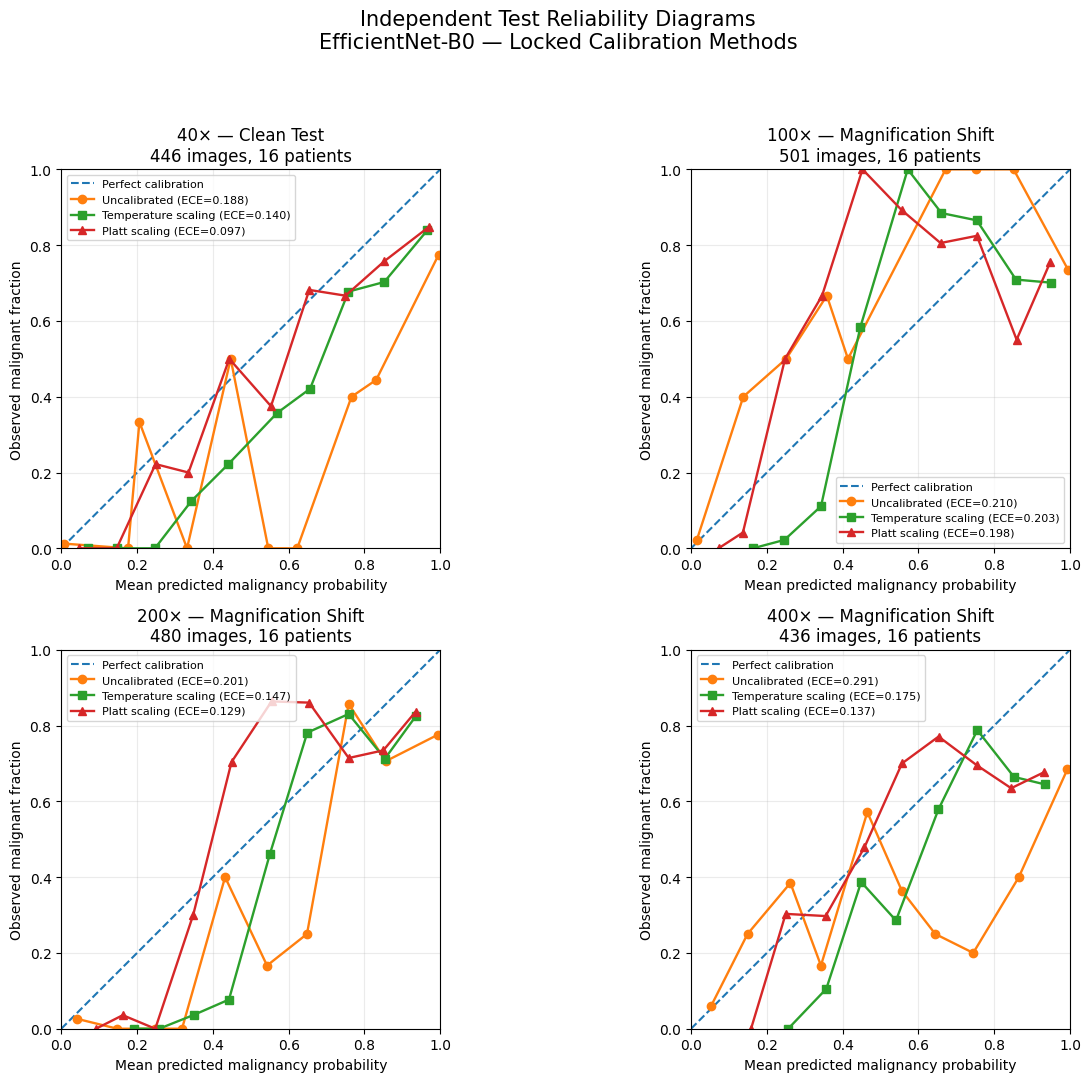

PASS: Four-panel reliability diagram saved.

RELIABILITY SUMMARY — ALL MAGNIFICATIONS


,magnification,method,n_images,observed_malignant_fraction,mean_predicted_probability,ece10_recalculated,nonempty_bins
0,40,Uncalibrated,446,0.60762,0.79144,0.18762,10
1,40,Temperature scaling,446,0.60762,0.74770,0.14008,10
2,40,Platt scaling,446,0.60762,0.69769,0.09735,10
3,100,Uncalibrated,501,0.60279,0.78368,0.21027,9
4,100,Temperature scaling,501,0.60279,0.73591,0.20311,9
5,100,Platt scaling,501,0.60279,0.67125,0.19792,10
6,200,Uncalibrated,480,0.65000,0.84855,0.20143,10
7,200,Temperature scaling,480,0.65000,0.76152,0.14691,9
8,200,Platt scaling,480,0.65000,0.68535,0.12932,10
9,400,Uncalibrated,436,0.58945,0.86325,0.29057,10



STAGE 8 — CELL 9 FINAL AUDIT
PASS: 40x reliability data verified.
PASS: 100x reliability data verified.
PASS: 200x reliability data verified.
PASS: 400x reliability data verified.
PASS: All three calibration methods visualized.
PASS: Ten equal-width calibration bins used.
PASS: All 120 reliability-bin rows saved.
PASS: All 12 reliability summaries saved.
PASS: ECE results reproduce Cell 7 exactly.
PASS: Four-panel reliability diagram saved.
PASS: Figure and output SHA-256 hashes verified.
PASS: Final CNN checkpoint unchanged.
PASS: Calibration parameters unchanged.
PASS: No retraining or refitting.
PASS: No Test-based model selection.

Figure: /content/breast-histology-calibration/results/independent_test/efficientnet_b0/test_reliability_diagrams_four_magnifications.png
Bin data: /content/breast-histology-calibration/results/independent_test/efficientnet_b0/test_reliability_bins_all_magnifications.csv
Summary: /content/breast-histology-calibration/results/independent_test/efficientnet

In [10]:

# ============================================================
# Reliability Diagrams and Calibration Visualization
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Verify independent Test and bootstrap outputs
# ------------------------------------------------------------

with open(
    TEST_METRICS_AUDIT_PATH,
    encoding="utf-8"
) as f:
    metrics_audit = json.load(f)

with open(
    BOOTSTRAP_AUDIT_PATH,
    encoding="utf-8"
) as f:
    bootstrap_audit = json.load(f)

assert bootstrap_audit["status"] == (
    "patient_bootstrap_completed"
)

assert sha256_file(
    ALL_TEST_IMAGE_PREDICTIONS_PATH
) == metrics_audit["test_predictions_sha256"]

assert sha256_file(
    TEST_METRICS_PATH
) == metrics_audit["test_metrics_sha256"]

assert sha256_file(
    BOOTSTRAP_CI_PATH
) == bootstrap_audit["output_sha256"][
    BOOTSTRAP_CI_PATH.name
]

assert sha256_file(
    CHECKPOINT_PATH
) == EXPECTED_MODEL_SHA256

assert sha256_file(
    PARAMETERS_PATH
) == calibration_lock[
    "calibration_parameters_sha256"
]

test_predictions = pd.read_csv(
    ALL_TEST_IMAGE_PREDICTIONS_PATH,
    dtype={
        "patient_id": str,
        "filename": str
    }
)

test_metrics = pd.read_csv(TEST_METRICS_PATH)

assert len(test_predictions) == 1863
assert len(test_metrics) == 12

assert test_predictions["filename"].is_unique

assert set(
    test_predictions["patient_id"]
) == test_patients

print("=" * 70)
print("STAGE 8 — RELIABILITY DIAGRAMS")
print("=" * 70)

print("PASS: Independent Test predictions verified.")
print("PASS: Performance metrics verified.")
print("PASS: Patient-level bootstrap results verified.")
print("PASS: Model and calibrator integrity verified.")

# ------------------------------------------------------------
# 2. Define methods and plotting specifications
# ------------------------------------------------------------

magnifications = [40, 100, 200, 400]

method_columns = {
    "Uncalibrated": "probability",
    "Temperature scaling": "temperature_probability",
    "Platt scaling": "platt_probability"
}

method_markers = {
    "Uncalibrated": "o",
    "Temperature scaling": "s",
    "Platt scaling": "^"
}

N_BINS = 10

expected_image_counts = {
    40: 446,
    100: 501,
    200: 480,
    400: 436
}

# ------------------------------------------------------------
# 3. Calculate reliability bins
#
# Exact same ten-bin definition as Cell 7:
#
# [0.0, 0.1), [0.1, 0.2), ... [0.9, 1.0]
#
# The final bin includes probability exactly 1.
# ------------------------------------------------------------

reliability_records = []
reliability_summary_records = []

for magnification in magnifications:

    subset = (
        test_predictions.loc[
            test_predictions["magnification"]
            == magnification
        ]
        .copy()
        .reset_index(drop=True)
    )

    assert len(subset) == expected_image_counts[
        magnification
    ]

    assert subset["patient_id"].nunique() == 16

    labels = subset[
        "label"
    ].to_numpy(dtype=np.int64)

    assert set(np.unique(labels)) == {0, 1}

    for method, column in method_columns.items():

        probabilities = subset[
            column
        ].to_numpy(dtype=np.float64)

        assert np.isfinite(probabilities).all()

        assert (
            (probabilities >= 0)
            &
            (probabilities <= 1)
        ).all()

        # Match the Cell 7 ECE bin assignment exactly.

        bin_indices = np.minimum(
            (probabilities * N_BINS).astype(int),
            N_BINS - 1
        )

        ece_from_bins = 0.0

        for bin_index in range(N_BINS):

            mask = (
                bin_indices == bin_index
            )

            n_images = int(mask.sum())

            bin_lower = (
                bin_index / N_BINS
            )

            bin_upper = (
                (bin_index + 1) / N_BINS
            )

            if n_images > 0:

                mean_probability = float(
                    probabilities[mask].mean()
                )

                observed_fraction = float(
                    labels[mask].mean()
                )

                calibration_gap = (
                    mean_probability - observed_fraction
                )

                weighted_absolute_gap = (
                    n_images / len(subset)
                ) * abs(calibration_gap)

                ece_from_bins += (
                    weighted_absolute_gap
                )

            else:

                # Empty bins are retained in the CSV.
                # They are not plotted and contribute
                # zero to ECE.

                mean_probability = np.nan
                observed_fraction = np.nan
                calibration_gap = np.nan
                weighted_absolute_gap = 0.0

            reliability_records.append({
                "magnification": magnification,
                "method": method,
                "bin_index": bin_index,
                "bin_lower": bin_lower,
                "bin_upper": bin_upper,
                "n_images": n_images,
                "mean_predicted_probability":
                    mean_probability,
                "observed_malignant_fraction":
                    observed_fraction,
                "calibration_gap":
                    calibration_gap,
                "weighted_absolute_gap":
                    weighted_absolute_gap
            })

        # ----------------------------------------------------
        # 4. Verify plotted ECE against saved Cell 7 metric
        # ----------------------------------------------------

        matching_metrics = test_metrics.loc[
            (
                test_metrics["magnification"]
                == magnification
            )
            &
            (
                test_metrics["method"]
                == method
            )
        ]

        assert len(matching_metrics) == 1

        saved_ece = float(
            matching_metrics["ece10"].iloc[0]
        )

        np.testing.assert_allclose(
            ece_from_bins,
            saved_ece,
            rtol=0,
            atol=1e-12
        )

        # Independently verify total image count.

        method_rows = [
            row
            for row in reliability_records
            if row["magnification"] == magnification
            and row["method"] == method
        ]

        assert sum(
            row["n_images"]
            for row in method_rows
        ) == len(subset)

        reliability_summary_records.append({
            "magnification": magnification,
            "method": method,
            "n_images": len(subset),
            "n_patients": subset[
                "patient_id"
            ].nunique(),
            "observed_malignant_fraction":
                float(labels.mean()),
            "mean_predicted_probability":
                float(probabilities.mean()),
            "ece10_recalculated":
                float(ece_from_bins),
            "ece10_saved":
                saved_ece,
            "nonempty_bins":
                sum(
                    row["n_images"] > 0
                    for row in method_rows
                )
        })

print("\nPASS: All reliability bins calculated.")
print("PASS: Recalculated ECE matches Cell 7.")
print("PASS: All image counts verified.")

# ------------------------------------------------------------
# 5. Save reliability-bin data
# ------------------------------------------------------------

reliability_bins = pd.DataFrame(
    reliability_records
)

reliability_summary = pd.DataFrame(
    reliability_summary_records
)

assert len(reliability_bins) == (
    4 * 3 * 10
)

assert len(reliability_summary) == 12

assert (
    reliability_bins
    .groupby(["magnification", "method"])[
        "n_images"
    ]
    .sum()
    .to_dict()
    ==
    {
        (magnification, method): count
        for magnification, count
        in expected_image_counts.items()
        for method in method_columns
    }
)

RELIABILITY_BINS_PATH = (
    STAGE8_RESULTS_DIR /
    "test_reliability_bins_all_magnifications.csv"
)

RELIABILITY_SUMMARY_PATH = (
    STAGE8_RESULTS_DIR /
    "test_reliability_summary.csv"
)

reliability_bins.to_csv(
    RELIABILITY_BINS_PATH,
    index=False,
    float_format="%.17g"
)

reliability_summary.to_csv(
    RELIABILITY_SUMMARY_PATH,
    index=False,
    float_format="%.17g"
)

assert len(pd.read_csv(
    RELIABILITY_BINS_PATH
)) == 120

assert len(pd.read_csv(
    RELIABILITY_SUMMARY_PATH
)) == 12

print("PASS: Reliability bins and summary saved.")

# ------------------------------------------------------------
# 6. Generate four-panel reliability diagram
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 11)
)

for ax, magnification in zip(
    axes.flat,
    magnifications
):

    # Ideal calibration reference.

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=1.5,
        label="Perfect calibration"
    )

    for method in method_columns:

        method_bins = (
            reliability_bins.loc[
                (
                    reliability_bins["magnification"]
                    == magnification
                )
                &
                (
                    reliability_bins["method"]
                    == method
                )
                &
                (
                    reliability_bins["n_images"] > 0
                )
            ]
            .sort_values("bin_index")
        )

        assert len(method_bins) > 0

        summary_row = reliability_summary.loc[
            (
                reliability_summary["magnification"]
                == magnification
            )
            &
            (
                reliability_summary["method"]
                == method
            )
        ]

        assert len(summary_row) == 1

        method_ece = float(
            summary_row[
                "ece10_recalculated"
            ].iloc[0]
        )

        # Plot only nonempty bins.
        # Points are located at the actual mean
        # predicted probability within each bin.

        ax.plot(
            method_bins[
                "mean_predicted_probability"
            ].to_numpy(),
            method_bins[
                "observed_malignant_fraction"
            ].to_numpy(),
            marker=method_markers[method],
            markersize=6,
            linewidth=1.7,
            label=f"{method} (ECE={method_ece:.3f})"
        )

    evaluation_type = (
        "Clean Test"
        if magnification == 40
        else "Magnification Shift"
    )

    ax.set_title(
        f"{magnification}× — {evaluation_type}\n"
        f"{expected_image_counts[magnification]} images, "
        "16 patients"
    )

    ax.set_xlabel(
        "Mean predicted malignancy probability"
    )

    ax.set_ylabel(
        "Observed malignant fraction"
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    ax.set_xticks(
        np.linspace(0, 1, 6)
    )

    ax.set_yticks(
        np.linspace(0, 1, 6)
    )

    ax.grid(
        True,
        alpha=0.25
    )

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    ax.legend(
        fontsize=8,
        loc="best"
    )

fig.suptitle(
    "Independent Test Reliability Diagrams\n"
    "EfficientNet-B0 — Locked Calibration Methods",
    fontsize=15
)

fig.tight_layout(
    rect=[0, 0, 1, 0.94]
)

# ------------------------------------------------------------
# 7. Save high-resolution plot
# ------------------------------------------------------------

RELIABILITY_FIGURE_PATH = (
    STAGE8_RESULTS_DIR /
    "test_reliability_diagrams_four_magnifications.png"
)

fig.savefig(
    RELIABILITY_FIGURE_PATH,
    dpi=250,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

assert RELIABILITY_FIGURE_PATH.is_file()

assert RELIABILITY_FIGURE_PATH.stat().st_size > 10000

print("PASS: Four-panel reliability diagram saved.")

# ------------------------------------------------------------
# 8. Save visualization provenance
# ------------------------------------------------------------

RELIABILITY_AUDIT_PATH = (
    STAGE8_RESULTS_DIR /
    "test_reliability_diagram_audit.json"
)

reliability_audit = {
    "stage": 8,
    "status": "reliability_diagrams_completed",
    "model": "efficientnet_b0",
    "test_patients": 16,
    "test_images": 1863,
    "magnifications": magnifications,
    "methods": list(method_columns.keys()),
    "positive_class": "Malignant",
    "calibration_bins": N_BINS,
    "binning": "equal_width",
    "bin_probability": "malignant",
    "final_bin_includes_one": True,
    "empty_bins_excluded_from_plot": True,
    "all_bins_retained_in_csv": True,
    "ece_reproduced_from_bins": True,
    "unit_of_evaluation": "source_image",
    "images_clustered_within_patients": True,
    "plots_are_descriptive": True,
    "confidence_intervals_plotted": False,
    "checkpoint_sha256":
        EXPECTED_MODEL_SHA256,
    "calibration_parameters_sha256":
        sha256_file(PARAMETERS_PATH),
    "test_predictions_sha256":
        sha256_file(
            ALL_TEST_IMAGE_PREDICTIONS_PATH
        ),
    "reliability_bins_sha256":
        sha256_file(RELIABILITY_BINS_PATH),
    "reliability_summary_sha256":
        sha256_file(RELIABILITY_SUMMARY_PATH),
    "figure_sha256":
        sha256_file(RELIABILITY_FIGURE_PATH),
    "cnn_retrained": False,
    "calibrators_refitted": False,
    "test_based_method_selection": False
}

with open(
    RELIABILITY_AUDIT_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        reliability_audit,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 9. Display summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RELIABILITY SUMMARY — ALL MAGNIFICATIONS")
print("=" * 70)

display(
    reliability_summary[
        [
            "magnification",
            "method",
            "n_images",
            "observed_malignant_fraction",
            "mean_predicted_probability",
            "ece10_recalculated",
            "nonempty_bins"
        ]
    ].round(5)
)

# ------------------------------------------------------------
# 10. Final audit
# ------------------------------------------------------------

assert sha256_file(
    CHECKPOINT_PATH
) == EXPECTED_MODEL_SHA256

assert sha256_file(
    PARAMETERS_PATH
) == calibration_lock[
    "calibration_parameters_sha256"
]

assert sha256_file(
    RELIABILITY_BINS_PATH
) == reliability_audit[
    "reliability_bins_sha256"
]

assert sha256_file(
    RELIABILITY_SUMMARY_PATH
) == reliability_audit[
    "reliability_summary_sha256"
]

assert sha256_file(
    RELIABILITY_FIGURE_PATH
) == reliability_audit[
    "figure_sha256"
]

print("\n" + "=" * 70)
print("STAGE 8 — CELL 9 FINAL AUDIT")
print("=" * 70)

print("PASS: 40x reliability data verified.")
print("PASS: 100x reliability data verified.")
print("PASS: 200x reliability data verified.")
print("PASS: 400x reliability data verified.")
print("PASS: All three calibration methods visualized.")
print("PASS: Ten equal-width calibration bins used.")
print("PASS: All 120 reliability-bin rows saved.")
print("PASS: All 12 reliability summaries saved.")
print("PASS: ECE results reproduce Cell 7 exactly.")
print("PASS: Four-panel reliability diagram saved.")
print("PASS: Figure and output SHA-256 hashes verified.")
print("PASS: Final CNN checkpoint unchanged.")
print("PASS: Calibration parameters unchanged.")
print("PASS: No retraining or refitting.")
print("PASS: No Test-based model selection.")

print("\nFigure:", RELIABILITY_FIGURE_PATH)
print("Bin data:", RELIABILITY_BINS_PATH)
print("Summary:", RELIABILITY_SUMMARY_PATH)
print("Audit:", RELIABILITY_AUDIT_PATH)


In [11]:

# ============================================================
# Final Verification and GitHub Results Packaging
# ============================================================

# ------------------------------------------------------------
# 1. Verify the frozen research artifacts
# ------------------------------------------------------------

assert sha256_file(
    CHECKPOINT_PATH
) == EXPECTED_MODEL_SHA256

assert sha256_file(
    PARAMETERS_PATH
) == calibration_lock[
    "calibration_parameters_sha256"
]

audit_checks = [
    (
        TEST_MANIFEST_PATH,
        test_manifest_audit[
            "combined_test_manifest_sha256"
        ]
    ),
    (
        ALL_TEST_IMAGE_PREDICTIONS_PATH,
        inference_audit[
            "combined_predictions_sha256"
        ]
    ),
    (
        TEST_METRICS_PATH,
        metrics_audit["test_metrics_sha256"]
    ),
    (
        RELIABILITY_BINS_PATH,
        reliability_audit["reliability_bins_sha256"]
    ),
    (
        RELIABILITY_SUMMARY_PATH,
        reliability_audit["reliability_summary_sha256"]
    ),
    (
        RELIABILITY_FIGURE_PATH,
        reliability_audit["figure_sha256"]
    )
]

for path, expected_hash in audit_checks:
    assert path.is_file()
    assert sha256_file(path) == expected_hash

for output_name, expected_hash in (
    bootstrap_audit["output_sha256"].items()
):
    path = STAGE8_RESULTS_DIR / output_name
    assert path.is_file()
    assert sha256_file(path) == expected_hash

print("PASS: Model and calibration parameters unchanged.")
print("PASS: Test manifests and predictions verified.")
print("PASS: Metrics and bootstrap results verified.")
print("PASS: Reliability figure and data verified.")

# ------------------------------------------------------------
# 2. Build the complete required-file inventory
# ------------------------------------------------------------

required_files = [
    TEST_MANIFEST_PATH,
    TEST_MANIFEST_AUDIT_PATH,
    ALL_TEST_IMAGE_PREDICTIONS_PATH,
    STAGE8_INFERENCE_AUDIT_PATH,
    TEST_METRICS_PATH,
    TEST_METRICS_AUDIT_PATH,
    BOOTSTRAP_REPLICATES_PATH,
    BOOTSTRAP_CI_PATH,
    BOOTSTRAP_METHOD_DIFFERENCES_PATH,
    BOOTSTRAP_MAGNIFICATION_DIFFERENCES_PATH,
    BOOTSTRAP_AUDIT_PATH,
    RELIABILITY_BINS_PATH,
    RELIABILITY_SUMMARY_PATH,
    RELIABILITY_FIGURE_PATH,
    RELIABILITY_AUDIT_PATH
]

for magnification in [40, 100, 200, 400]:

    required_files.append(
        test_manifest_paths[magnification]
    )

    required_files.extend(
        test_prediction_paths[magnification]
    )

    required_files.append(
        test_prediction_audit_paths[magnification]
    )

required_files = [
    Path(path).resolve()
    for path in required_files
]

assert len(required_files) == 31
assert len(set(required_files)) == 31

assert all(
    path.is_file()
    for path in required_files
)

assert all(
    path.is_relative_to(REPO_ROOT.resolve())
    for path in required_files
)

assert not any(
    path.suffix.lower() in {".pt", ".pth", ".ckpt"}
    for path in required_files
)

print("PASS: All 31 expected Stage 8 source files located.")
print("PASS: No model checkpoint included.")

# ------------------------------------------------------------
# 3. Independently verify per-magnification outputs
# ------------------------------------------------------------

for magnification in [40, 100, 200, 400]:

    audit_path = (
        test_prediction_audit_paths[magnification]
    )

    with open(
        audit_path,
        encoding="utf-8"
    ) as f:
        per_mag_audit = json.load(f)

    patch_path, image_path = (
        test_prediction_paths[magnification]
    )

    assert sha256_file(
        patch_path
    ) == per_mag_audit[
        "patch_predictions_sha256"
    ]

    assert sha256_file(
        image_path
    ) == per_mag_audit[
        "image_predictions_sha256"
    ]

    assert sha256_file(
        test_manifest_paths[magnification]
    ) == per_mag_audit[
        "input_manifest_sha256"
    ]

    assert per_mag_audit[
        "checkpoint_sha256"
    ] == EXPECTED_MODEL_SHA256

    assert per_mag_audit[
        "calibration_refitted"
    ] is False

    print(f"PASS: {magnification}x result provenance verified.")

# ------------------------------------------------------------
# 4. Generate a Stage 8 methodology summary
# ------------------------------------------------------------

final_metrics = pd.read_csv(
    TEST_METRICS_PATH
)

assert len(final_metrics) == 12

markdown_lines = [
    "| Magnification | Method | AUROC | ECE10 | Brier | NLL |",
    "|---|---|---:|---:|---:|---:|"
]

for _, row in final_metrics.iterrows():

    markdown_lines.append(
        f"| {int(row['magnification'])}x "
        f"| {row['method']} "
        f"| {row['auroc']:.4f} "
        f"| {row['ece10']:.4f} "
        f"| {row['brier']:.4f} "
        f"| {row['nll']:.4f} |"
    )

results_table = "\n".join(markdown_lines)

STAGE8_README_PATH = (
    STAGE8_RESULTS_DIR /
    "STAGE8_RESULTS_README.md"
)

readme_text = f"""# Stage 8 — Independent Test Evaluation

## Research objective

Evaluate confidence calibration and discrimination
of a frozen EfficientNet-B0 breast histopathology
classifier under BreaKHis magnification shift.

## Data partition

- Development: 49 patients
- Calibration: 16 patients
- Independent Test: 16 patients
- Test benign patients: 5
- Test malignant patients: 11
- Test images: 1,863
- Test patches: 29,671

Test image counts:

- 40x: 446 images
- 100x: 501 images
- 200x: 480 images
- 400x: 436 images

The 40x Test data represent clean internal evaluation.
The other magnifications represent magnification shift.

## Locked model and preprocessing

- Architecture: EfficientNet-B0
- Final checkpoint: Epoch 5
- Model checkpoint SHA-256: {EXPECTED_MODEL_SHA256}
- Image aggregation: mean patch logit
- Patch size: 224 x 224
- Candidate grid: 4 x 4
- Maximum patches per image: 16
- Minimum tissue fraction: 0.20

The original Development preprocessing operator,
including the fixed 0.98 resize factor, was
applied at every magnification.

This is NOT physical-resolution harmonization.

## Locked probability calibration

Temperature scaling:

- T = {LOCKED_TEMPERATURE}

Platt scaling:

- slope = {LOCKED_PLATT_SLOPE}
- intercept = {LOCKED_PLATT_INTERCEPT}

Both calibrators were fitted on Calibration
patients before independent Test evaluation.

Neither calibrator was refitted on Test data.

## Test metrics

{results_table}

Average precision is the implementation used
for the AUPRC summary.

ECE uses ten equal-width malignant-probability
bins, with the final bin including 1.0.

Classification metrics use probability >= 0.5.

## Statistical uncertainty

- 1,000 bootstrap resamples
- Random seed: 631
- Sampling unit: patient
- Sampling with replacement
- Stratified by patient diagnosis
- Five benign and eleven malignant patient draws
  per resample
- Same draws across magnifications and methods
- Repeated sampled patients retain all their images
- 95% percentile confidence intervals

These intervals are exploratory because there
are only 16 independent Test patients.

## Main observations

AUROC declined under all three shifted
magnifications relative to the 40x Test set.

The calibrated probabilities showed lower
ECE, Brier score, and NLL than uncalibrated
probabilities in the reported point estimates.

The paired patient-bootstrap ECE intervals
supported reductions at 400x, but the ECE
difference intervals at 40x, 100x, and 200x
included zero.

Calibration did not change AUROC because
the fitted transformations preserved ranking.

The results do not establish clinical safety,
clinical effectiveness, or external
generalization.

## Reproducibility

This directory contains the inference
predictions, evaluation metrics, patient-level
bootstrap results, reliability-bin data,
figure, and integrity audits.

Source images and final CNN weights are not
included in this results package.

The Stage 8 notebook must be committed
separately under Notebooks/.

No Test-based model selection, CNN retraining,
or calibration refitting was performed.
"""

STAGE8_README_PATH.write_text(
    readme_text,
    encoding="utf-8"
)

assert STAGE8_README_PATH.is_file()

print("PASS: Stage 8 methodology README generated.")

# ------------------------------------------------------------
# 5. Create an SHA-256 file inventory
# ------------------------------------------------------------

package_source_files = sorted(
    required_files + [STAGE8_README_PATH.resolve()],
    key=lambda path: str(path)
)

file_records = []

for path in package_source_files:

    file_records.append({
        "relative_path": str(
            path.relative_to(REPO_ROOT.resolve())
        ),
        "sha256": sha256_file(path),
        "size_bytes": path.stat().st_size
    })

file_inventory = pd.DataFrame(file_records)

STAGE8_FILE_INVENTORY_PATH = (
    STAGE8_RESULTS_DIR /
    "stage8_package_file_inventory.csv"
)

file_inventory.to_csv(
    STAGE8_FILE_INVENTORY_PATH,
    index=False
)

assert len(file_inventory) == 32

print("PASS: SHA-256 inventory created.")

# ------------------------------------------------------------
# 6. Create ZIP with preserved GitHub folder paths
# ------------------------------------------------------------

STAGE8_COMPLETE_BACKUP_PATH = Path(
    "/content/CIS631_Stage8_Complete_Results_For_GitHub.zip"
)

package_files = (
    package_source_files
    + [STAGE8_FILE_INVENTORY_PATH.resolve()]
)

with zipfile.ZipFile(
    STAGE8_COMPLETE_BACKUP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for path in package_files:

        archive.write(
            path,
            arcname=str(
                path.relative_to(REPO_ROOT.resolve())
            )
        )

# ------------------------------------------------------------
# 7. Independently verify ZIP contents and hashes
# ------------------------------------------------------------

with zipfile.ZipFile(
    STAGE8_COMPLETE_BACKUP_PATH,
    "r"
) as archive:

    assert archive.testzip() is None

    archived_names = set(
        archive.namelist()
    )

    expected_names = {
        str(path.relative_to(REPO_ROOT.resolve()))
        for path in package_files
    }

    assert archived_names == expected_names

    assert len(archived_names) == 33

    for _, record in file_inventory.iterrows():

        archived_bytes = archive.read(
            record["relative_path"]
        )

        archived_hash = hashlib.sha256(
            archived_bytes
        ).hexdigest()

        assert archived_hash == record["sha256"]

    assert not any(
        name.lower().endswith(
            (".pt", ".pth", ".ckpt")
        )
        for name in archived_names
    )

print("PASS: ZIP integrity verified.")
print("PASS: All 33 packaged files accounted for.")
print("PASS: Archived file hashes match originals.")
print("PASS: GitHub directory structure preserved.")

# ------------------------------------------------------------
# 8. Final Stage 8 report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STAGE 8 — FINAL COMPLETION AUDIT")
print("=" * 70)

print("PASS: Independent Test cohort verified.")
print("PASS: All four magnifications evaluated.")
print("PASS: All 29,671 patch predictions preserved.")
print("PASS: All 1,863 image predictions preserved.")
print("PASS: All three probability methods evaluated.")
print("PASS: Classification and calibration metrics saved.")
print("PASS: 1,000 patient-level bootstrap resamples saved.")
print("PASS: Paired method differences saved.")
print("PASS: Magnification-shift differences saved.")
print("PASS: Four-panel reliability figure saved.")
print("PASS: Reliability bins reproduce ECE.")
print("PASS: All result integrity hashes verified.")
print("PASS: Stage 8 methodology documented.")
print("PASS: GitHub-ready results package created.")
print("PASS: Final CNN checkpoint remains unchanged.")
print("PASS: Both calibrators remain unchanged.")
print("PASS: No Test-based model selection or refitting.")

print("\nPackage:", STAGE8_COMPLETE_BACKUP_PATH)

print(
    "ZIP size (MB):",
    round(
        STAGE8_COMPLETE_BACKUP_PATH.stat().st_size
        / (1024 ** 2),
        2
    )
)

print("Files inside ZIP:", len(package_files))

large_files = file_inventory.loc[
    file_inventory["size_bytes"] > 25 * 1024 * 1024
]

if not large_files.empty:
    print(
        "\nWARNING: Some individual files exceed 25 MB."
    )
    print(
        "They may require a different GitHub upload method."
    )
    display(
        large_files[
            ["relative_path", "size_bytes"]
        ]
    )

print("\nDownloading final Stage 8 results backup...")

files.download(
    str(STAGE8_COMPLETE_BACKUP_PATH)
)


PASS: Model and calibration parameters unchanged.
PASS: Test manifests and predictions verified.
PASS: Metrics and bootstrap results verified.
PASS: Reliability figure and data verified.
PASS: All 31 expected Stage 8 source files located.
PASS: No model checkpoint included.
PASS: 40x result provenance verified.
PASS: 100x result provenance verified.
PASS: 200x result provenance verified.
PASS: 400x result provenance verified.
PASS: Stage 8 methodology README generated.
PASS: SHA-256 inventory created.
PASS: ZIP integrity verified.
PASS: All 33 packaged files accounted for.
PASS: Archived file hashes match originals.
PASS: GitHub directory structure preserved.

STAGE 8 — FINAL COMPLETION AUDIT
PASS: Independent Test cohort verified.
PASS: All four magnifications evaluated.
PASS: All 29,671 patch predictions preserved.
PASS: All 1,863 image predictions preserved.
PASS: All three probability methods evaluated.
PASS: Classification and calibration metrics saved.
PASS: 1,000 patient-level b

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>